In [3]:
import warnings

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning - Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning - Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Machine Learning - Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

# Display & Warning Configuration
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization Configuration
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
df = pd.read_csv("Blockchain_Cryptocurrency_Transaction_Risk_Dataset.csv")
print(f"Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

Dataset loaded successfully.
Rows    : 9,000
Columns : 16


In [5]:
# Display the first five records
display(df.head())

# Display dataset dimensions
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

# Display column names and data types
schema = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non-null": df.notna().sum().values,
    "unique_values": df.nunique().values
})
display(schema)

,transaction_id,wallet_id,transaction_amount,transaction_fee,block_confirmation_time,input_count,output_count,wallet_age_days,total_wallet_transactions,avg_wallet_transaction_value,cross_border_flag,mixing_service_used,darknet_association_score,transaction_velocity_24h,unusual_pattern_score,risk_label
0,TX1,W25795,40.248537,0.003070,25,6,5,1776,7168,6.435886,0,0,0.105,168,0.677,0
1,TX2,W10860,48.366438,0.000580,144,19,6,1751,6198,4.183257,1,1,0.764,152,0.698,0
2,TX3,W86820,13.430678,0.007468,481,10,15,2051,4489,18.743126,0,0,0.784,115,0.062,0
3,TX4,W64886,24.741803,0.007486,293,3,6,2808,8436,17.446633,0,0,0.051,83,0.604,0
4,TX5,W16265,4.306719,0.006740,210,13,19,262,3746,19.854658,0,0,0.497,74,0.483,0


Dataset shape: 9,000 rows x 16 columns


,column,dtype,non-null,unique_values
0,transaction_id,object,9000,9000
1,wallet_id,object,9000,8593
2,transaction_amount,float64,9000,8999
3,transaction_fee,float64,9000,6005
4,block_confirmation_time,int64,9000,595
5,input_count,int64,9000,19
6,output_count,int64,9000,19
7,wallet_age_days,int64,9000,3563
8,total_wallet_transactions,int64,9000,5949
9,avg_wallet_transaction_value,float64,9000,8999


In [6]:
# Data Quality Assessment
# Missing value analysis
missing_summary = (
    df.isna()
    .sum()
    .to_frame(name="missing_count")
    .assign(
        missing_percentage=lambda x: (
            x["missing_count"] / len(df) * 100
        ).round(2)
    )
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
print("Missing Value Summary")
print("-" * 40)
if missing_summary.empty:
      print("No missing values detected.")
else:
    display(missing_summary)
# Duplicate analysis
duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print("\nDuplicate Analysis")
print("-" * 40)
print(f"Duplicate rows      : {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Missing Value Summary
----------------------------------------
No missing values detected.

Duplicate Analysis
----------------------------------------
Duplicate rows      : 0
Duplicate percentage: 0.00%


In [7]:
# Target Variable Inspection
TARGET = "risk_label"

# Validate target column
if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found in the dataset.")
    
# Target distribution
target_summary = (
    df[TARGET]
    .value_counts(dropna=False)
    .rename_axis(TARGET)
    .reset_index(name="count")
)
target_summary["percentage"] = (
    target_summary["count"] / len(df) * 100
).round(2)
display(target_summary)

# Basic target statistics
print(f"Target variable : {TARGET}")
print(f"Unique classes  : {df[TARGET].nunique(dropna=True)}")
print(f"Class values    : {sorted(df[TARGET].dropna().unique())}")



,risk_label,count,percentage
0,0,7607,84.52
1,1,1393,15.48


Target variable : risk_label
Unique classes  : 2
Class values    : [0, 1]


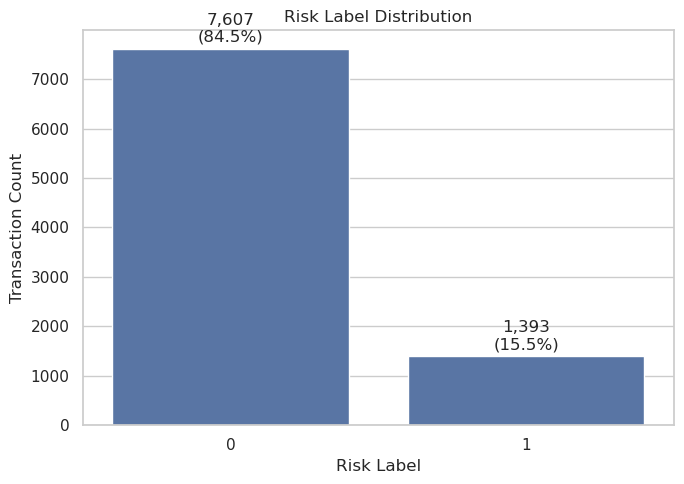

In [8]:
# Visualize target distribution
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=TARGET,
    order=sorted(df[TARGET].dropna().unique())
)
plt.title("Risk Label Distribution")
plt.xlabel("Risk Label")
plt.ylabel("Transaction Count")

# Add percentage labels
total = len(df)

for container in ax.containers:
    labels = []
    for bar in container:
        count = int(bar.get_height())
        percentage = count / total * 100
        labels.append(f"{count:,}\n({percentage:.1f}%)")

    ax.bar_label(container, labels=labels, padding=3)
plt.tight_layout()
plt.show()

In [9]:
# Numerical Feature Summary

# Select numerical columns
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

# Exclude target variable from feature summary
numeric_features = [
    column for column in numeric_features
    if column != TARGET 
]

# Generate descriptive statistics
numeric_summary = (
    df[numeric_features]
    .describe()
    .T
    .round(4)
)

# Add additional statistics
numeric_summary["missing"] = df[numeric_features].isna().sum()
numeric_summary["unique"] = df[numeric_features].nunique()

# Reorder columns for readability
numeric_summary = numeric_summary[
    [
        "count",
        "unique",
        "missing",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
]
    ]
display(numeric_summary)

,count,unique,missing,mean,std,min,25%,50%,75%,max
transaction_amount,9000.0,8999,0,24.8173,14.4025,0.0036,12.3558,24.5787,37.4169,49.9903
transaction_fee,9000.0,6005,0,0.0051,0.0029,0.0001,0.0027,0.0052,0.0076,0.0100
block_confirmation_time,9000.0,595,0,302.0042,172.1583,5.0000,155.0000,301.0000,451.0000,599.0000
input_count,9000.0,19,0,9.9162,5.4672,1.0000,5.0000,10.0000,15.0000,19.0000
output_count,9000.0,19,0,9.9304,5.4737,1.0000,5.0000,10.0000,15.0000,19.0000
wallet_age_days,9000.0,3563,0,1971.4213,1148.2547,1.0000,984.7500,1965.0000,2953.2500,3999.0000
total_wallet_transactions,9000.0,5949,0,5038.5690,2902.6884,1.0000,2540.0000,5076.0000,7580.0000,9999.0000
avg_wallet_transaction_value,9000.0,8999,0,12.4680,7.1967,0.0168,6.2849,12.4008,18.7755,24.9922
cross_border_flag,9000.0,2,0,0.1998,0.3999,0.0000,0.0000,0.0000,0.0000,1.0000
mixing_service_used,9000.0,2,0,0.1011,0.3015,0.0000,0.0000,0.0000,0.0000,1.0000


In [10]:
# Categorical, Binary & Identifier Features

# Identify non-numerical columns
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Identify potential identifier columns
identifier_candidates = [
    column
    for column in df.columns
    if column.lower().endswith("_id")
    or column.lower() in {"id", "transaction_id", "wallet_id"}
]

# Identify low-cardinality numerical features
binary_features = [
    column
    for column in df.select_dtypes(include=np.number).columns
    if column != TARGET and df[column].nunique(dropna=True) <= 2
]
print("Categorical Features")
print("-" * 40)

if categorical_features:
    for column in categorical_features:
        print(
            f"{column:<30} "
            f"unique={df[column].nunique(dropna=True):,}"
        )
else:
     print("No categorical features detected.")
    
print("\nBinary / Low-Cardinality Numerical Features")
print("-" * 40)

if binary_features:
     for column in binary_features:
         values = sorted(df[column].dropna().unique().tolist())
         print(f"{column:<30} values={values}")
else:
    print("No binary numerical features detected.")

Categorical Features
----------------------------------------
transaction_id                 unique=9,000
wallet_id                      unique=8,593

Binary / Low-Cardinality Numerical Features
----------------------------------------
cross_border_flag              values=[0, 1]
mixing_service_used            values=[0, 1]


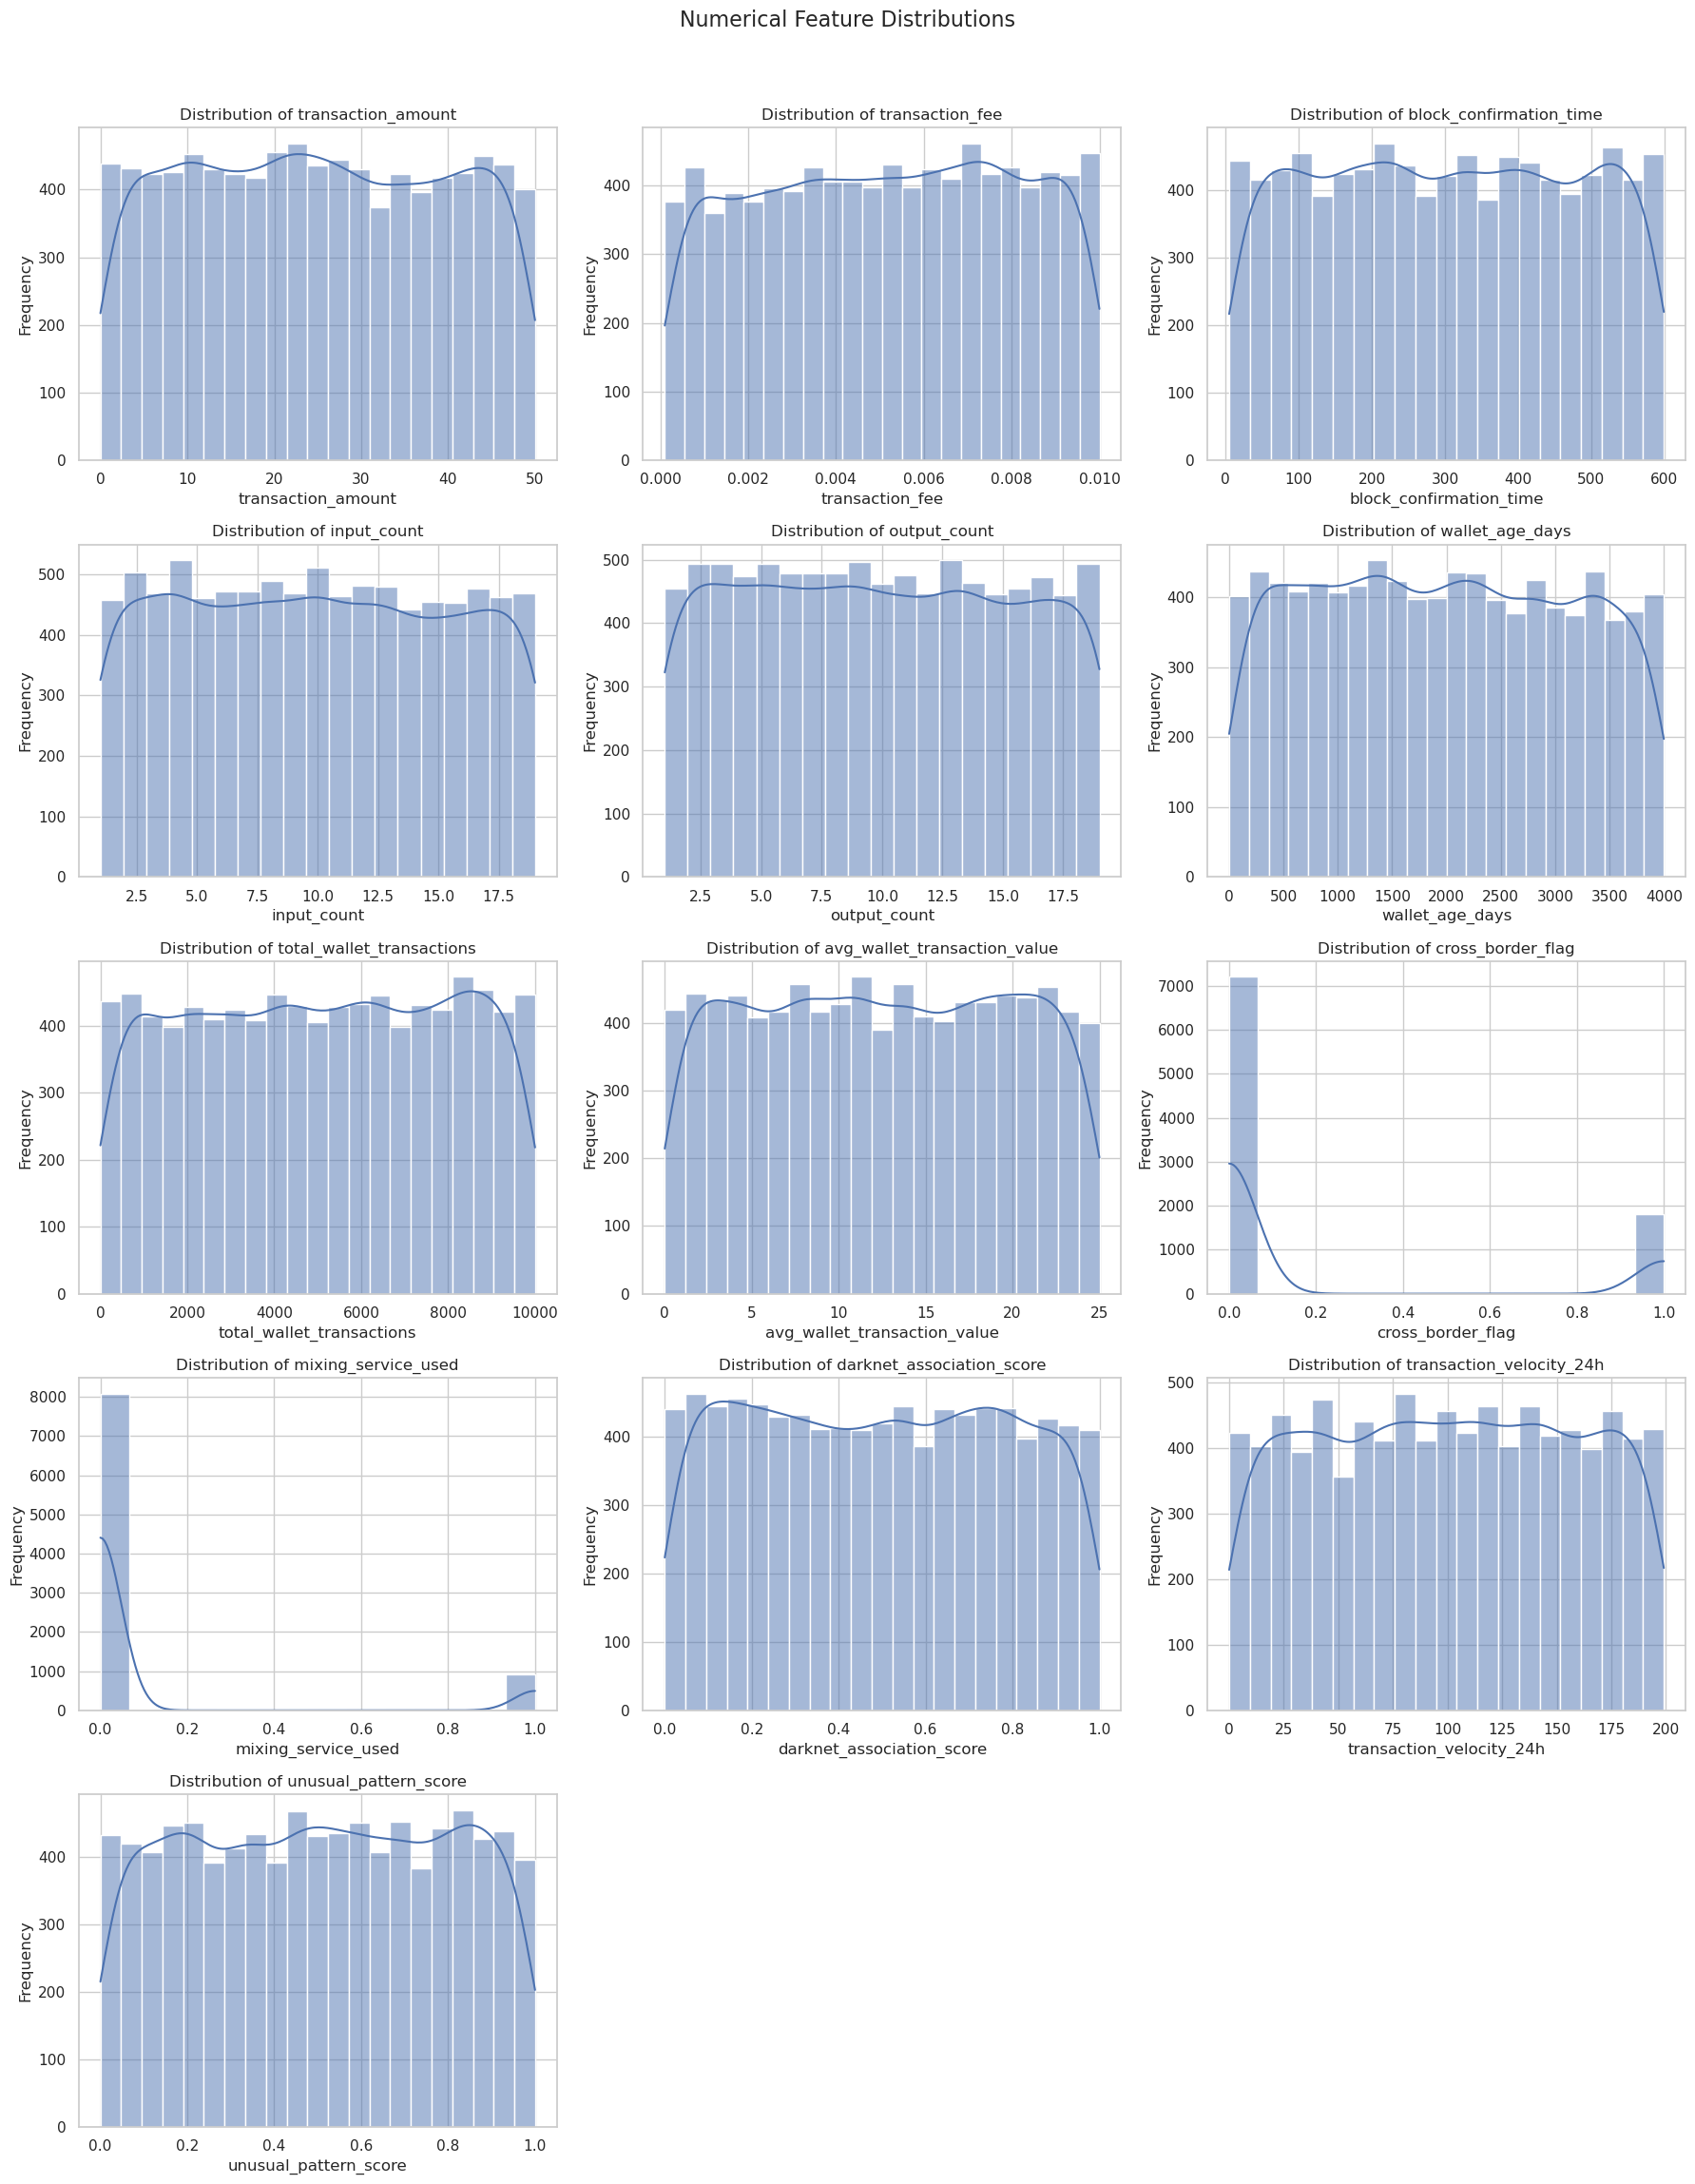

In [11]:
# Numerical Feature Distributions

# Create a copy to avoid modifying the original dataset
eda_numeric = df[numeric_features].copy()

# Determine subplot layout
n_features = len(numeric_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.5 * n_rows)
)
# Flatten axes for consistent iteration
axes = np.asarray(axes).flatten()

# Plot distributions
for ax, feature in zip(axes, numeric_features):
    sns.histplot(
        data=eda_numeric,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")
# Hide unused axes
for ax in axes[n_features:]:
    ax.set_visible(False)

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()            

In [12]:
# Outlier & Distribution Diagnostics
def calculate_outlier_summary(data, features):
    """
    Calculate distribution and IQR-based outlier statistics
    for numerical features.
    """
    summary = []

    for feature in features:
        series = data[feature].dropna()

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
    
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
    
        outlier_mask = (
            (series < lower_bound) |
            (series > upper_bound)
        )

        summary.append({
            "feature": feature,
            "skewness": series.skew(),
            "q1": q1,
            "median": series.median(),
            "q3": q3,
            "min": series.min(),
            "max": series.max(),
            "outlier_count": outlier_mask.sum(),
            "outlier_percentage": (
                    outlier_mask.mean() * 100
                )
        })
    return (
         pd.DataFrame(summary)
        .sort_values("outlier_percentage", ascending=False)
        .reset_index(drop=True)
    )
    
outlier_summary = calculate_outlier_summary(
         df,
    numeric_features
    )
display(
    outlier_summary.style.format({
        "skewness": "{:.3f}",
        "q1": "{:.4f}",
        "median": "{:.4f}",
        "q3": "{:.4f}",
        "min": "{:.4f}",
        "max": "{:.4f}",
        "outlier_percentage": "{:.2f}%"
    })
)

,feature,skewness,q1,median,q3,min,max,outlier_count,outlier_percentage
0,cross_border_flag,1.502,0.0000,0.0000,0.0000,0.0000,1.0000,1798,19.98%
1,mixing_service_used,2.647,0.0000,0.0000,0.0000,0.0000,1.0000,910,10.11%
2,block_confirmation_time,0.006,155.0000,301.0000,451.0000,5.0000,599.0000,0,0.00%
3,transaction_fee,-0.042,0.0027,0.0052,0.0076,0.0001,0.0100,0,0.00%
4,transaction_amount,0.022,12.3558,24.5787,37.4169,0.0036,49.9903,0,0.00%
5,output_count,0.028,5.0000,10.0000,15.0000,1.0000,19.0000,0,0.00%
6,input_count,0.027,5.0000,10.0000,15.0000,1.0000,19.0000,0,0.00%
7,total_wallet_transactions,-0.025,2540.0000,5076.0000,7580.0000,1.0000,9999.0000,0,0.00%
8,wallet_age_days,0.037,984.7500,1965.0000,2953.2500,1.0000,3999.0000,0,0.00%
9,avg_wallet_transaction_value,-0.002,6.2849,12.4008,18.7755,0.0168,24.9922,0,0.00%


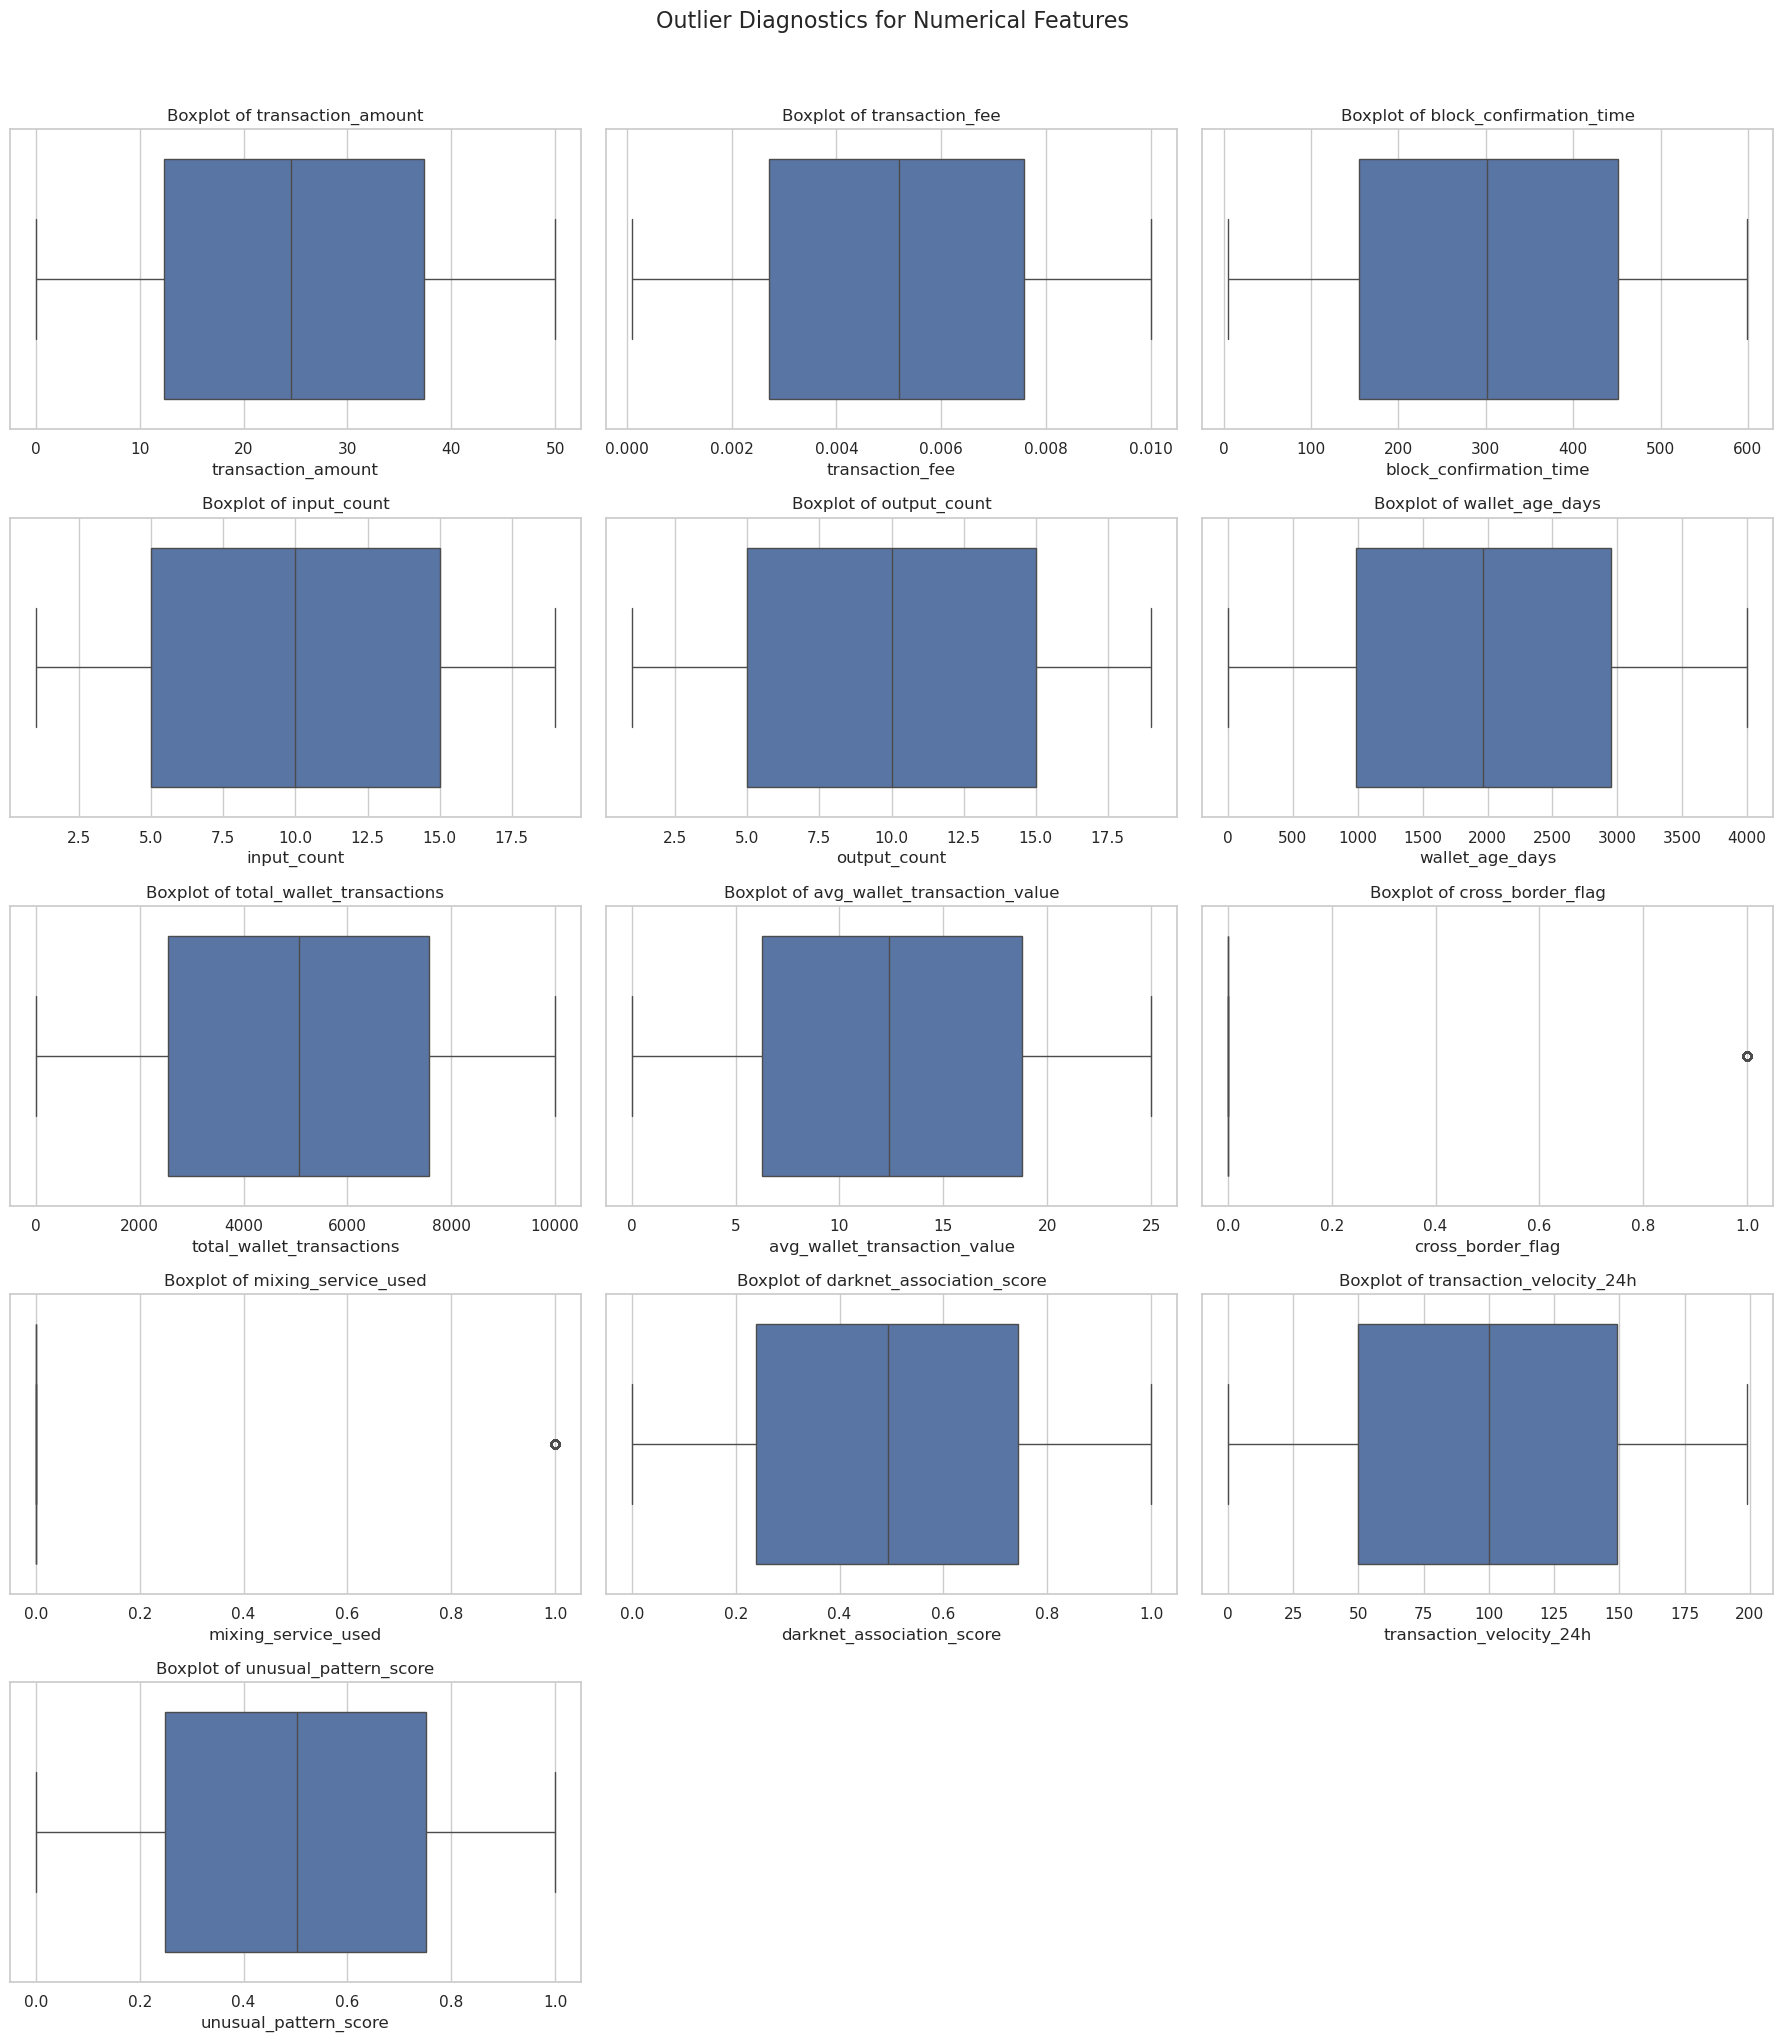

In [13]:
# Boxplot visualization
n_features = len(numeric_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)
axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(
        data=df,
        x=feature,
        ax=ax
    )
    ax.set_title(f"Boxplot of {feature}")
    ax.set_xlabel(feature)

    for ax in axes[n_features:]:
        ax.set_visible(False)
plt.suptitle(
    "Outlier Diagnostics for Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [14]:
# Risk Profile by Numerical Features

# Calculate group-level statistics by risk label
risk_profile = (
    df.groupby(TARGET)[numeric_features]
    .agg(["mean", "median"])
    .T
)
display(risk_profile.round(4))

risk_label                                   0          1
transaction_amount           mean      24.8412    24.6866
                             median    24.5975    24.5065
transaction_fee              mean       0.0052     0.0050
                             median     0.0052     0.0049
block_confirmation_time      mean     300.4715   310.3740
                             median   300.0000   315.0000
input_count                  mean       9.9263     9.8615
                             median    10.0000    10.0000
output_count                 mean       9.9841     9.6375
                             median    10.0000     9.0000
wallet_age_days              mean    1972.2680  1966.7976
                             median  1973.0000  1931.0000
total_wallet_transactions    mean    5047.6740  4988.8478
                             median  5087.0000  4983.0000
avg_wallet_transaction_value mean      12.4315    12.6673
                             median    12.3188    12.7888
cross_border_flag            mean       0.1976     0.2118
                             median     0.0000     0.0000
mixing_service_used          mean       0.0998     0.1084
                             median     0.0000     0.0000
darknet_association_score    mean       0.4950     0.4873
                             median     0.4970     0.4870
transaction_velocity_24h     mean      99.4283   102.0337
                             median   100.0000   102.0000
unusual_pattern_score        mean       0.5033     0.4879
                             median     0.5050     0.4880

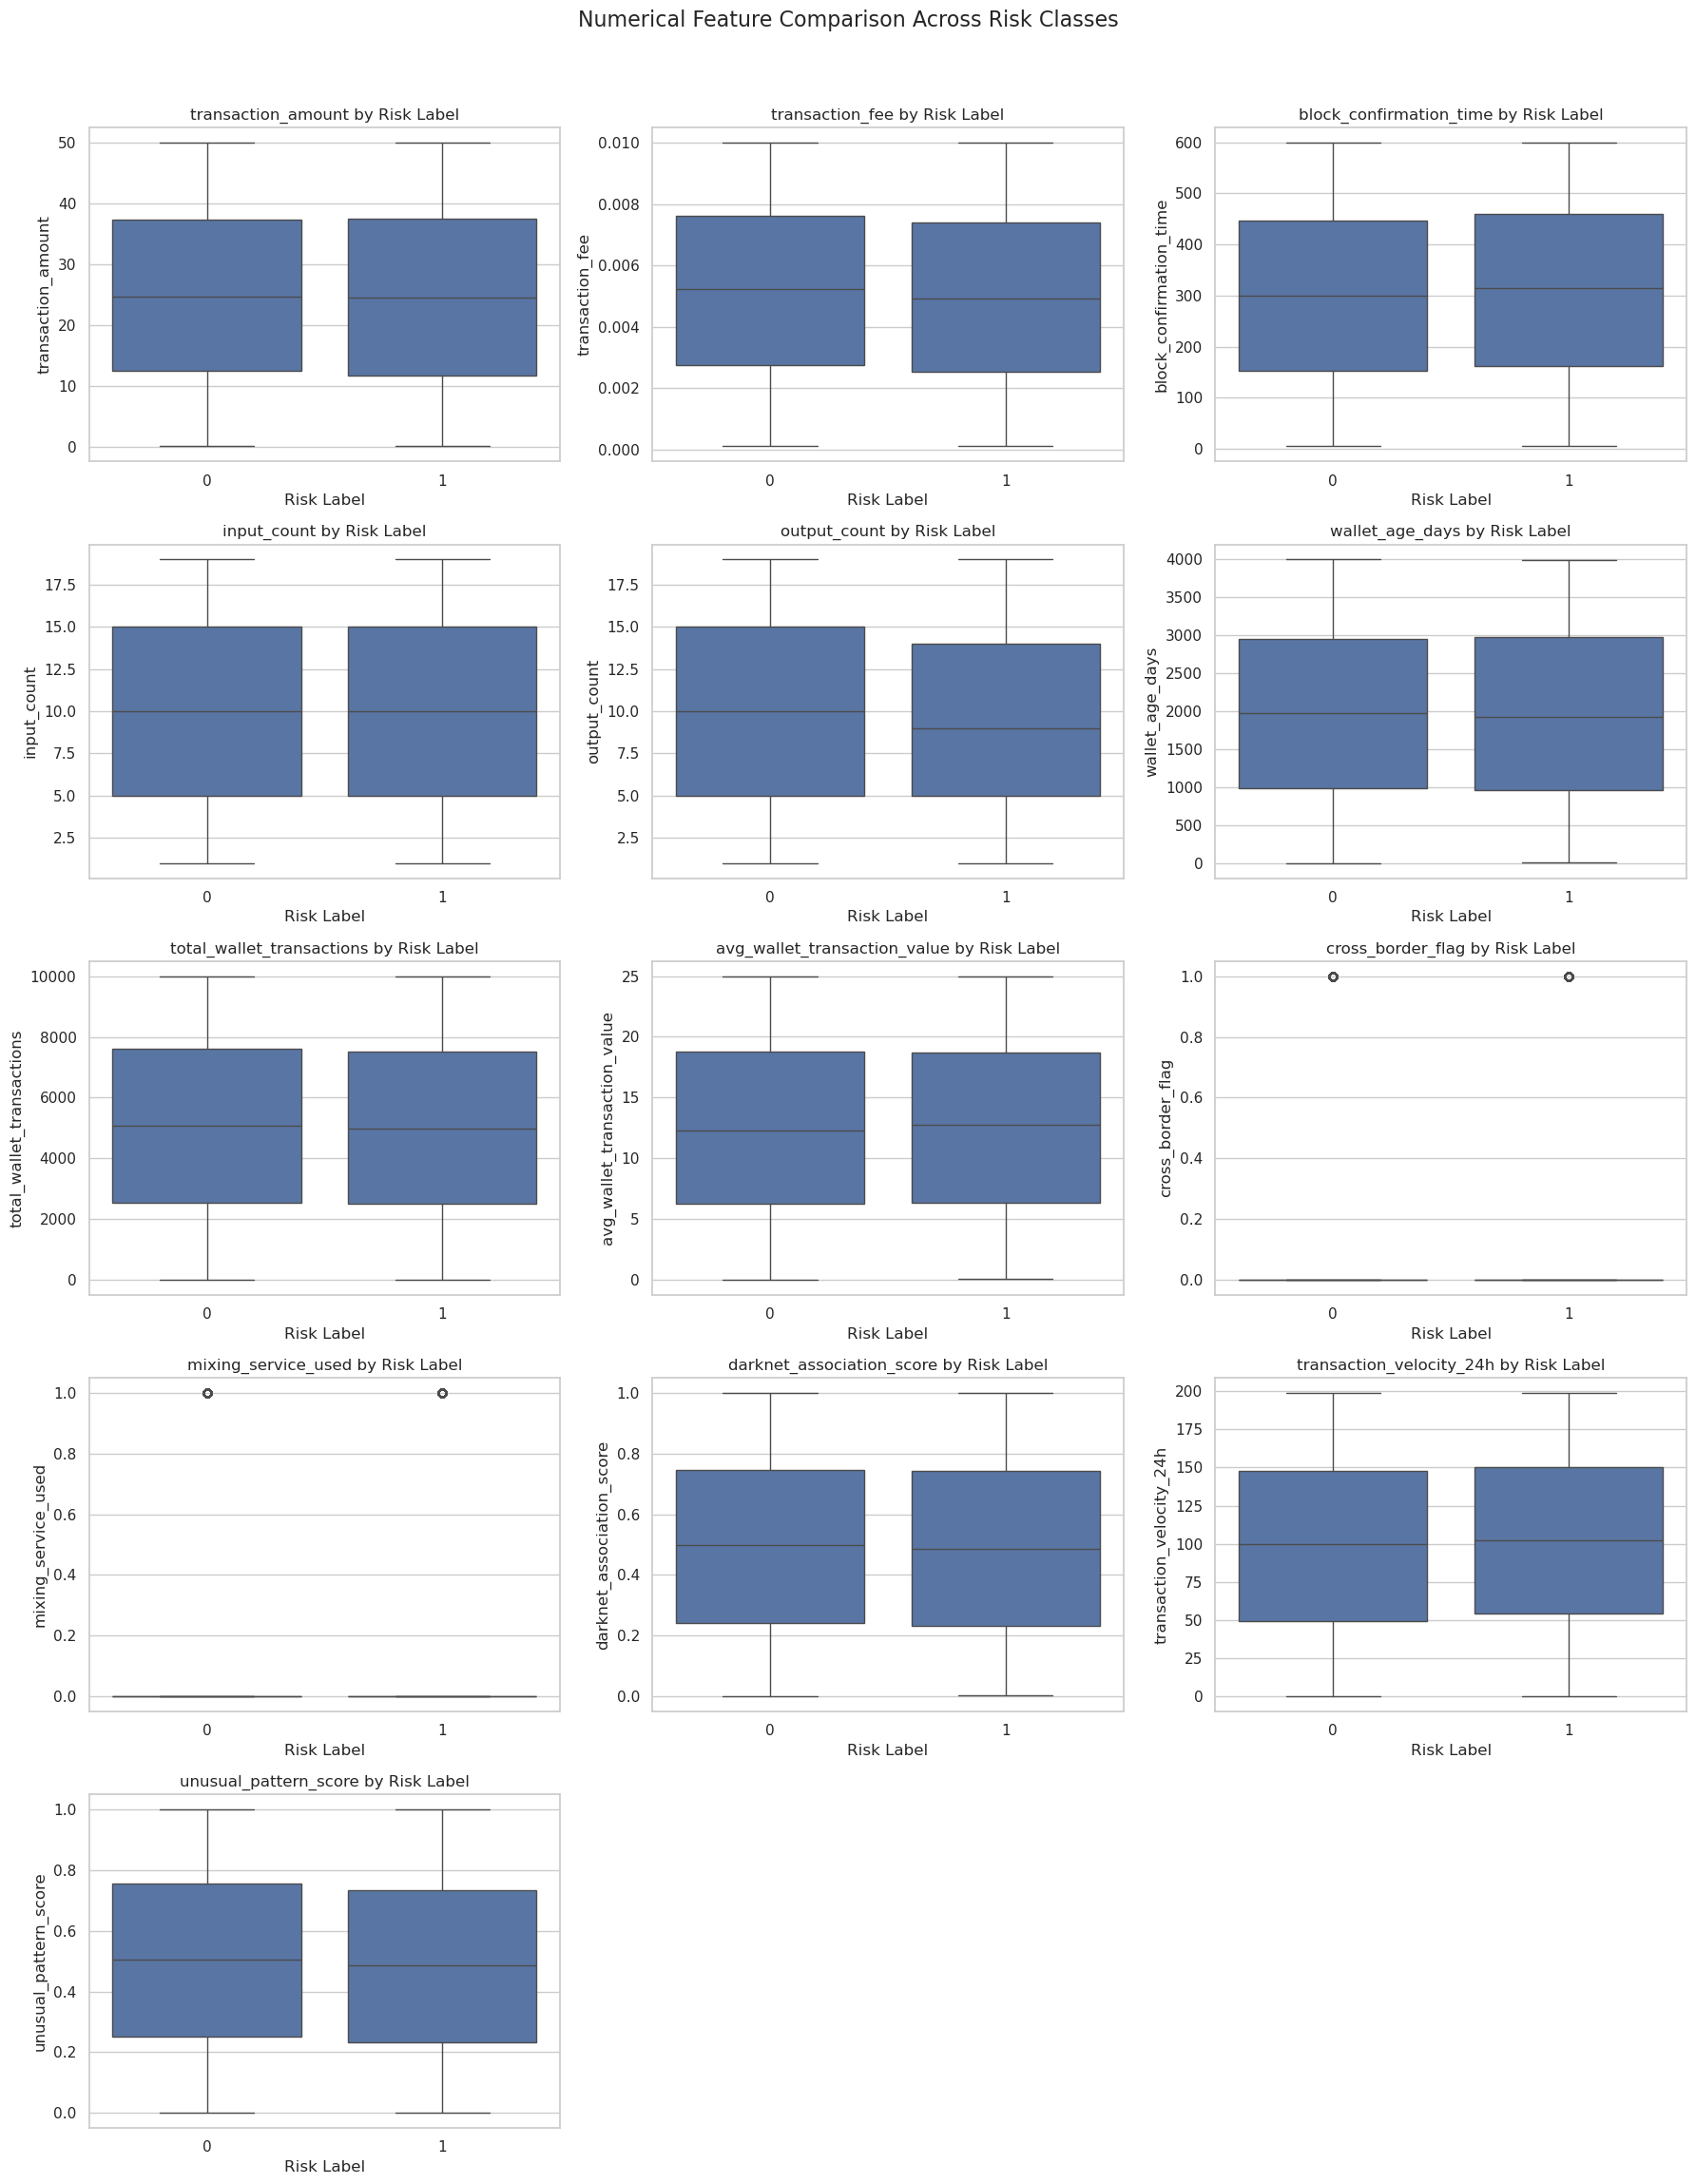

In [15]:
# Visual comparison
n_features = len(numeric_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))


fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Risk Label")
    ax.set_xlabel("Risk Label")
    ax.set_ylabel(feature)

for ax in axes[n_features:]:
    ax.set_visible(False)
plt.suptitle(
    "Numerical Feature Comparison Across Risk Classes",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [16]:
# Binary Risk Indicator Analysis

# Identify binary features excluding the target
binary_risk_features = [
    feature
    for feature in binary_features
    if feature != TARGET
]
if not binary_risk_features:
     print("No binary risk indicators detected.")
else:

    binary_summary = []

    for feature in binary_risk_features:
        grouped = (
             df.groupby(TARGET)[feature]
            .mean()
            .mul(100)
        )
        for risk_class, percentage in grouped.items():
            binary_summary.append({
                "feature": feature,
                "risk_label": risk_class,
                "percentage_flagged": percentage
            })

    binary_summary = pd.DataFrame(binary_summary)
    display(
        binary_summary.style.format({
            "percentage_flagged": "{:.2f}%"
        })
    )
            

,feature,risk_label,percentage_flagged
0,cross_border_flag,0,19.76%
1,cross_border_flag,1,21.18%
2,mixing_service_used,0,9.98%
3,mixing_service_used,1,10.84%


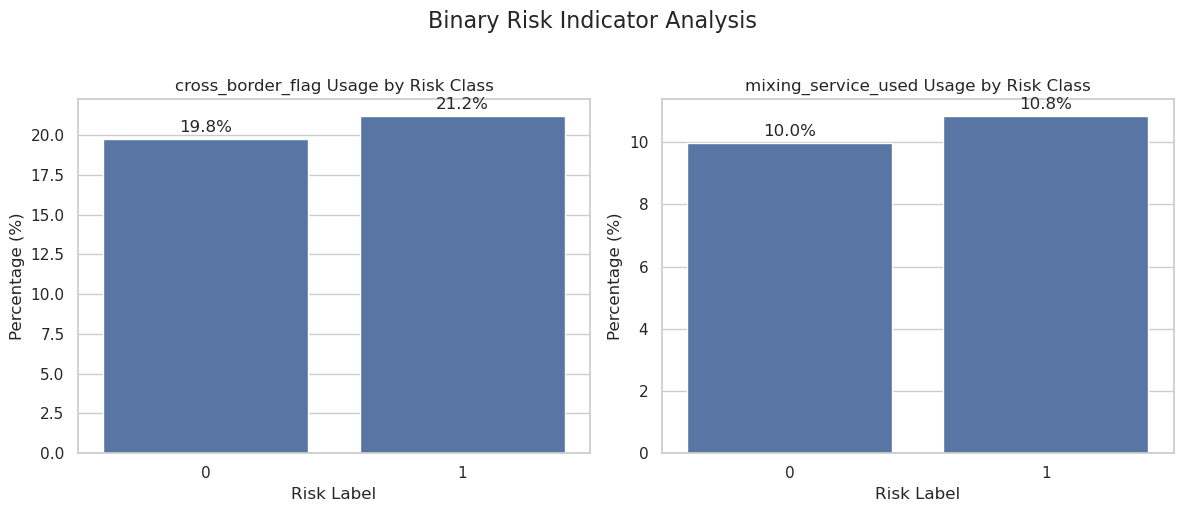

In [17]:
# Visualization
n_features = len(binary_risk_features)
n_cols = min(2, n_features)
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
n_rows,
n_cols,
figsize=(12, 5 * n_rows)
)
axes = np.atleast_1d(axes).flatten()

for ax, feature in zip(axes, binary_risk_features):
    plot_data = (
    df.groupby(TARGET)[feature]
        .mean()
        .mul(100)
        .reset_index()
    )
    sns.barplot(
    data=plot_data,
    x=TARGET,
    y=feature,
    ax=ax
    )
    ax.set_title(f"{feature} Usage by Risk Class")
    ax.set_xlabel("Risk Label")
    ax.set_ylabel("Percentage (%)")
    
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3
            )
for ax in axes[n_features:]:
    ax.set_visible(False)

plt.suptitle(
    "Binary Risk Indicator Analysis",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()      


In [18]:
# Risk Indicator Relationship Analysis

# Define risk-related features explicitly
risk_indicator_features = [
    "darknet_association_score",
    "transaction_velocity_24h",
    "unusual_pattern_score"
]

# Keep only features available in the dataset
risk_indicator_features = [
    feature
    for feature in risk_indicator_features
    if feature in df.columns
]
if not risk_indicator_features:
    print("No predefined risk indicator features found.")
else:
    risk_correlation = (
        df[risk_indicator_features + [TARGET]]
        .corr(numeric_only=True)[TARGET]
        .drop(TARGET)
        .sort_values(key=abs, ascending=False)
    )
    print("Correlation with Risk Label")
    print("-" * 40)

    display(
        risk_correlation
        .to_frame(name="correlation")
        .style.format("{:.4f}")
    )

Correlation with Risk Label
----------------------------------------


,correlation
unusual_pattern_score,-0.0193
transaction_velocity_24h,0.0164
darknet_association_score,-0.0097


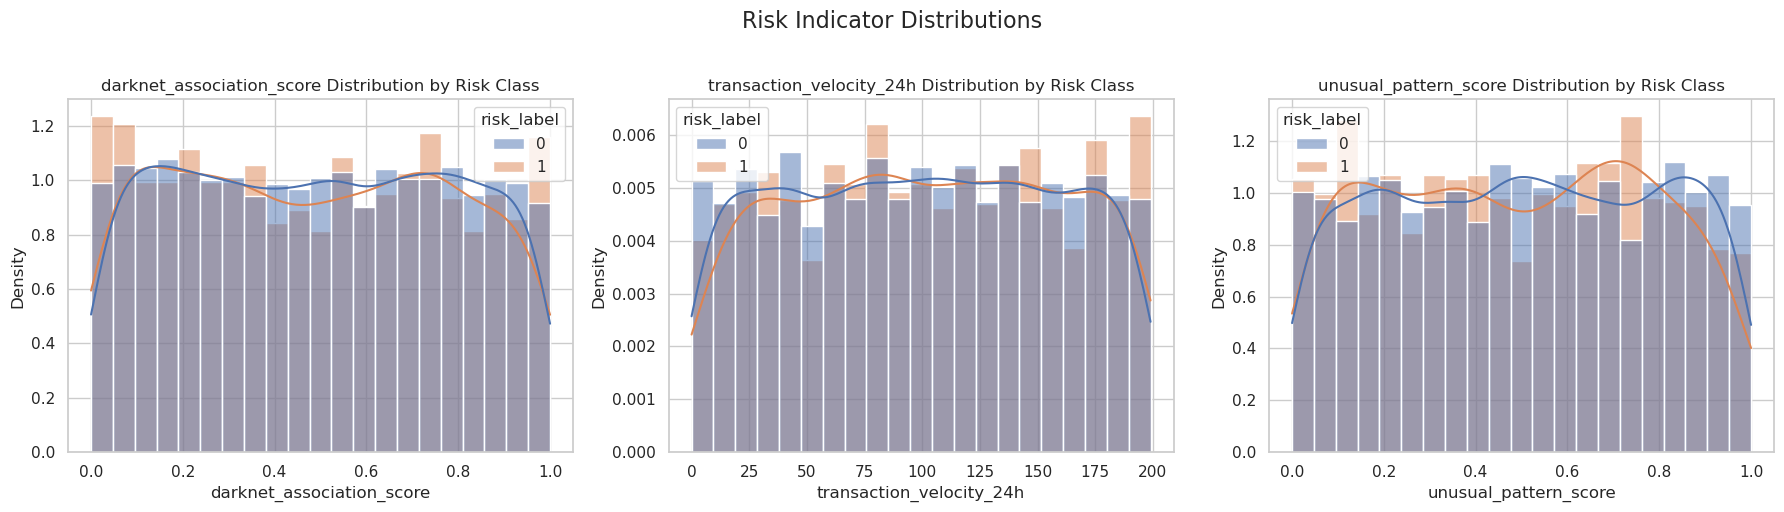

In [19]:
# Distribution by risk class
n_features = len(risk_indicator_features)
n_cols = min(3, n_features)
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)
axes = np.atleast_1d(axes).flatten()

for ax, feature in zip(axes, risk_indicator_features):
    sns.histplot(
        data=df,
        x=feature,
        hue=TARGET,
        kde=True,
        stat="density",
        common_norm=False,
        ax=ax
     )
    
    ax.set_title(f"{feature} Distribution by Risk Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")

for ax in axes[n_features:]:
    ax.set_visible(False)
    
plt.suptitle(
    "Risk Indicator Distributions",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


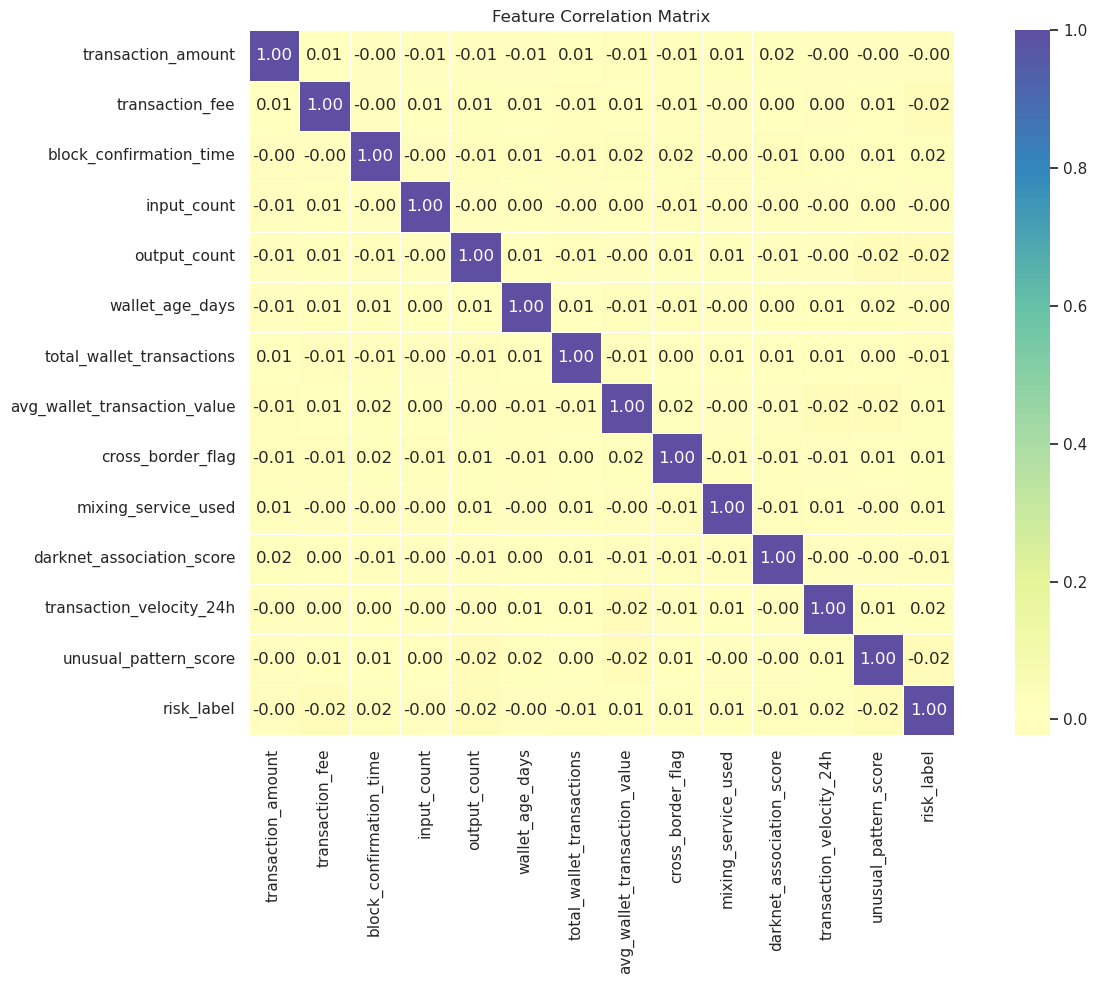

In [20]:
# Feature Correlation Analysis

# Include target for correlation analysis
correlation_features = numeric_features + [TARGET]

correlation_matrix = df[correlation_features].corr()

# Correlation heatmap
plt.figure(
    figsize=(14, 10)
)
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Spectral",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# Strong feature correlations
correlation_threshold = 0.70

upper_triangle = correlation_matrix.where(
    np.triu(
         np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

In [21]:
# Transaction Amount vs Risk
FEATURE = "transaction_amount"

if FEATURE not in df.columns:
    raise KeyError(
        f"Required feature '{FEATURE}' was not found in the dataset."
    )

# Group-level statistics
transaction_amount_summary = (
    df.groupby(TARGET)[FEATURE]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(4)
)
display(transaction_amount_summary)

,count,mean,median,std,min,max
risk_label,,,,,,
0,7607,24.8412,24.5975,14.3890,0.0036,49.9903
1,1393,24.6866,24.5065,14.4805,0.0215,49.9837


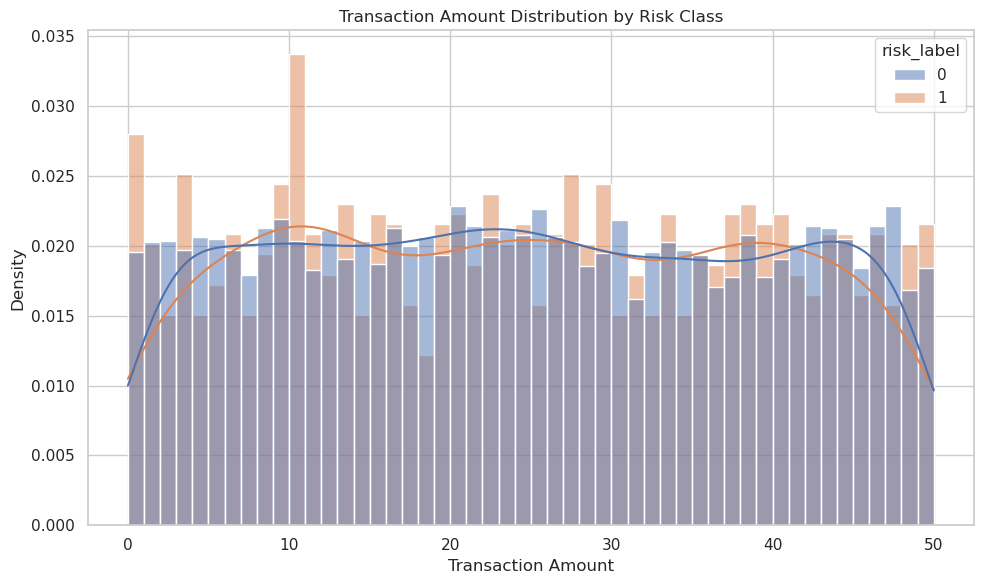

In [22]:
# Distribution by risk class
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x=FEATURE,
    hue=TARGET,
    kde=True,
    stat="density",
    common_norm=False,
    bins=50
)
plt.title("Transaction Amount Distribution by Risk Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

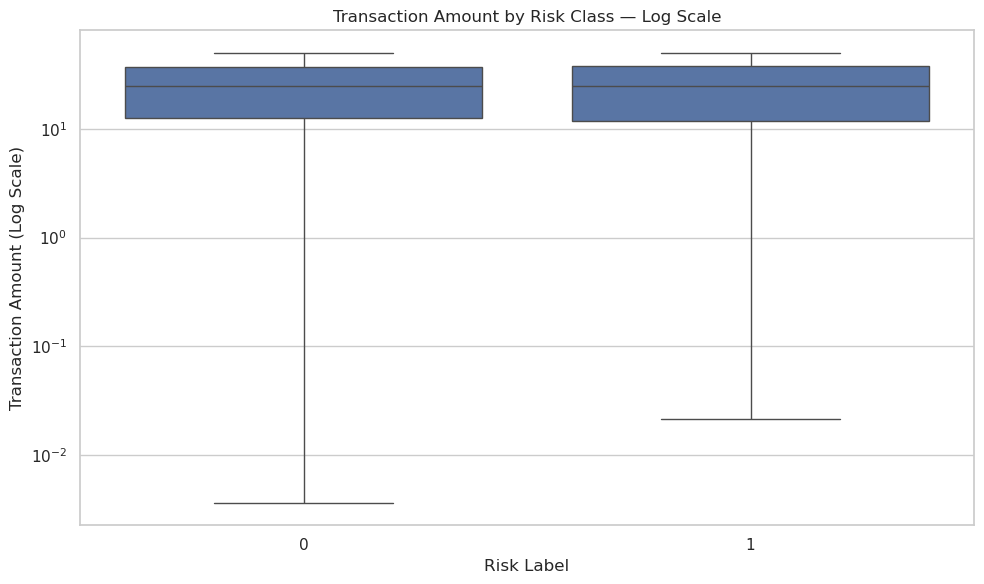

In [23]:
# Log-scale visualization
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x=TARGET,
    y=FEATURE
)
plt.yscale("log")
plt.title("Transaction Amount by Risk Class — Log Scale")
plt.xlabel("Risk Label")
plt.ylabel("Transaction Amount (Log Scale)")
plt.tight_layout()
plt.show()

In [24]:
# Wallet Behavior Analysis
wallet_features = [
    "wallet_age_days",
    "total_wallet_transactions",
    "avg_wallet_transaction_value"
]

# Validate required features
missing_wallet_features = [
    feature
    for feature in wallet_features
    if feature not in df.columns
]
if missing_wallet_features:
     raise KeyError(
        f"Missing wallet features: {missing_wallet_features}"
    )

# Group-level comparison
wallet_summary = (
    df.groupby(TARGET)[wallet_features]
    .agg(["mean", "median"])
    .round(4)
)
display(wallet_summary)


wallet_age_days         total_wallet_transactions          \
                      mean  median                      mean  median   
risk_label                                                             
0                1972.2680  1973.0                 5047.6740  5087.0   
1                1966.7976  1931.0                 4988.8478  4983.0   

           avg_wallet_transaction_value           
                                   mean   median  
risk_label                                        
0                               12.4315  12.3188  
1                               12.6673  12.7888

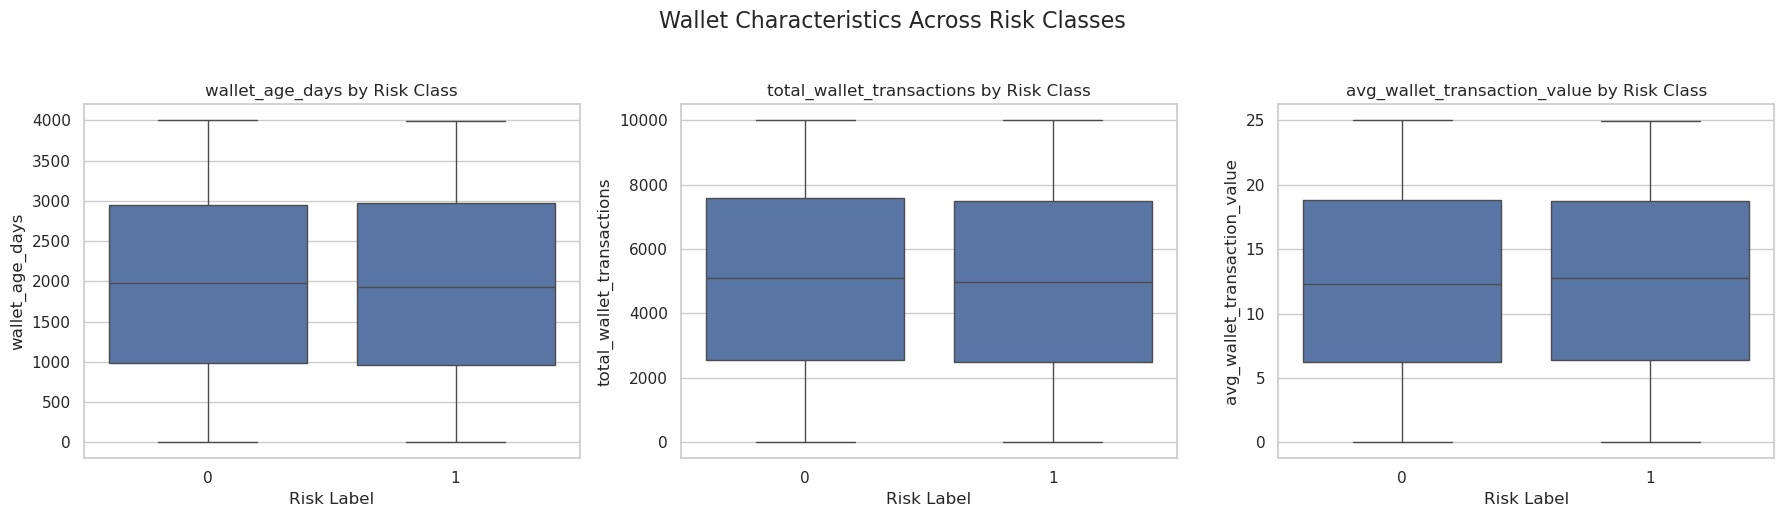

In [25]:
# Visual comparison
n_features = len(wallet_features)
n_cols = 3
n_rows = 1

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5)
)

for ax, feature in zip(axes, wallet_features):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Risk Class")
    ax.set_xlabel("Risk Label")
    ax.set_ylabel(feature)
plt.suptitle(
    "Wallet Characteristics Across Risk Classes",
    fontsize=16,
    y=1.03
)
plt.tight_layout()
plt.show()    

In [26]:
# Transaction Velocity & Behavioral Risk Analysis
behavioral_features= [
    "transaction_velocity_24h",
    "unusual_pattern_score"
]

# Validate required features
missing_behavioral_features = [
    feature
    for feature in behavioral_features
    if feature not in df.columns
]
if missing_behavioral_features:
    raise KeyError(
        f"Missing behavioral features: {missing_behavioral_features}"
    )
# Group-level statistics
behavioral_summary = (
    df.groupby(TARGET)[behavioral_features]
    .agg(
        ["mean", "median", "std"]
    )
    .round(4)
)

display(behavioral_summary)

transaction_velocity_24h                 unusual_pattern_score  \
                               mean median      std                  mean   
risk_label                                                                  
0                           99.4283  100.0  57.3160                0.5033   
1                          102.0337  102.0  57.3172                0.4879   

                           
           median     std  
risk_label                 
0           0.505  0.2884  
1           0.488  0.2855

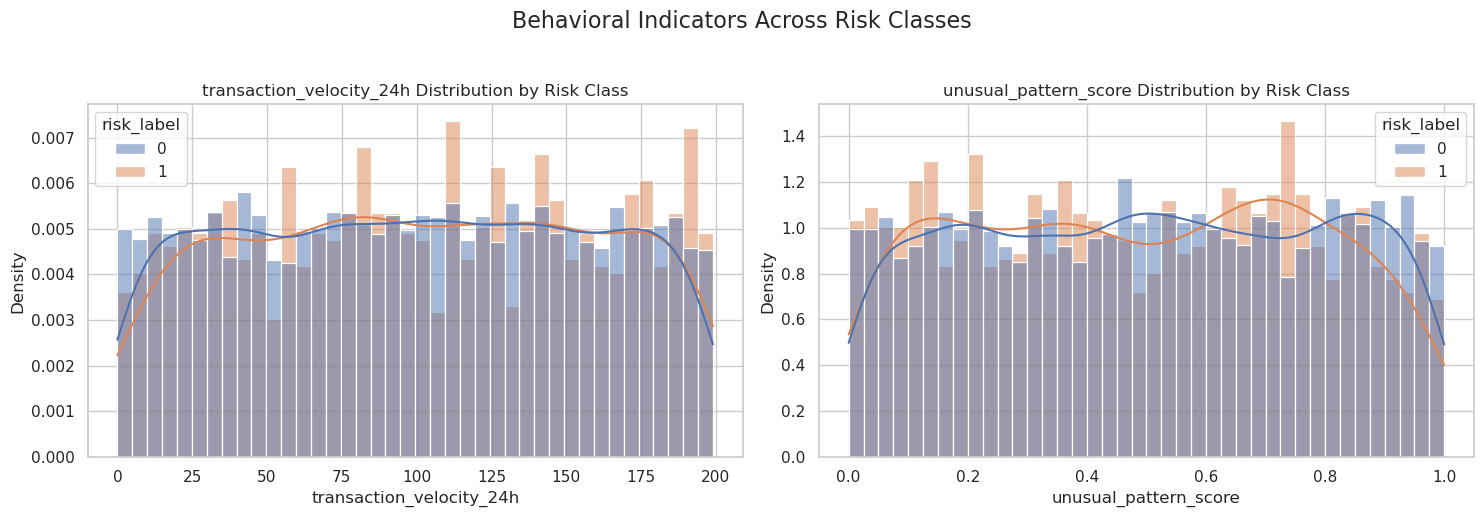

In [27]:
# Distribution comparison
fig, axes = plt.subplots(
    1,
    len(behavioral_features),
    figsize=(15, 5)
) 
for ax, feature in zip(axes, behavioral_features):
    sns.histplot(
        data=df,
        x=feature,
        hue=TARGET,
        kde=True,
        stat="density",
        common_norm=False,
        bins=40,
        ax=ax
    )
    ax.set_title(
        f"{feature} Distribution by Risk Class"
    )
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")

plt.suptitle(
    "Behavioral Indicators Across Risk Classes",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

In [28]:
# Risk rate across velocity quantiles
velocity_feature = "transaction_velocity_24h"

velocity_bins = pd.qcut(
    df[velocity_feature],
    q=5,
    duplicates="drop"
)
velocity_risk_rate = (
      df.groupby(
        velocity_bins,
        observed=True
    )[TARGET]
    .mean()
    .mul(100)
    .reset_index(name="risk_rate")
)
display(
    velocity_risk_rate.style.format({
        "risk_rate": "{:.2f}%"
    })
)

,transaction_velocity_24h,risk_rate
0,"(-0.001, 40.0]",14.84%
1,"(40.0, 81.0]",15.05%
2,"(81.0, 120.0]",15.50%
3,"(120.0, 159.0]",15.80%
4,"(159.0, 199.0]",16.22%


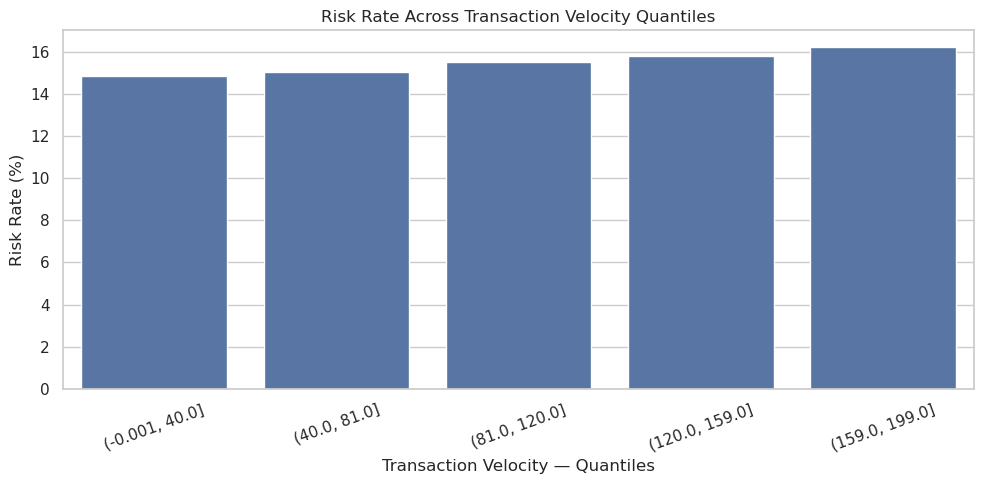

In [29]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=velocity_risk_rate,
    x=velocity_feature,
    y="risk_rate"
)

plt.title(
    "Risk Rate Across Transaction Velocity Quantiles"
)
plt.xlabel("Transaction Velocity — Quantiles")
plt.ylabel("Risk Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [30]:
# Cross-Border & Mixing Service Risk Analysis
binary_risk_features = [
    "cross_border_flag",
    "mixing_service_used"
]
# Validate required features
missing_features = [
    feature
    for feature in binary_risk_features
    if feature not in df.columns
]
if missing_features:
    raise KeyError(
        f"Missing required features: {missing_features}"
    )

# Calculate risk rate for each indicator
risk_rate_records = []

for feature in binary_risk_features:
    grouped = (
        df.groupby(feature)[TARGET]
        .agg(
            transaction_count="count",
            risk_rate="mean"
        )
        .reset_index()
    )
    grouped["risk_rate"] = (
        grouped["risk_rate"] * 100
    ).round(2)
    grouped.insert(
        0,
        "feature",
        feature
    )
    risk_rate_records.append(grouped)

risk_rate_summary = pd.concat(
    risk_rate_records,
    ignore_index=True
)

display(risk_rate_summary)

,feature,cross_border_flag,transaction_count,risk_rate,mixing_service_used
0,cross_border_flag,0.0,7202,15.25,NaN
1,cross_border_flag,1.0,1798,16.41,NaN
2,mixing_service_used,NaN,8090,15.35,0.0
3,mixing_service_used,NaN,910,16.59,1.0


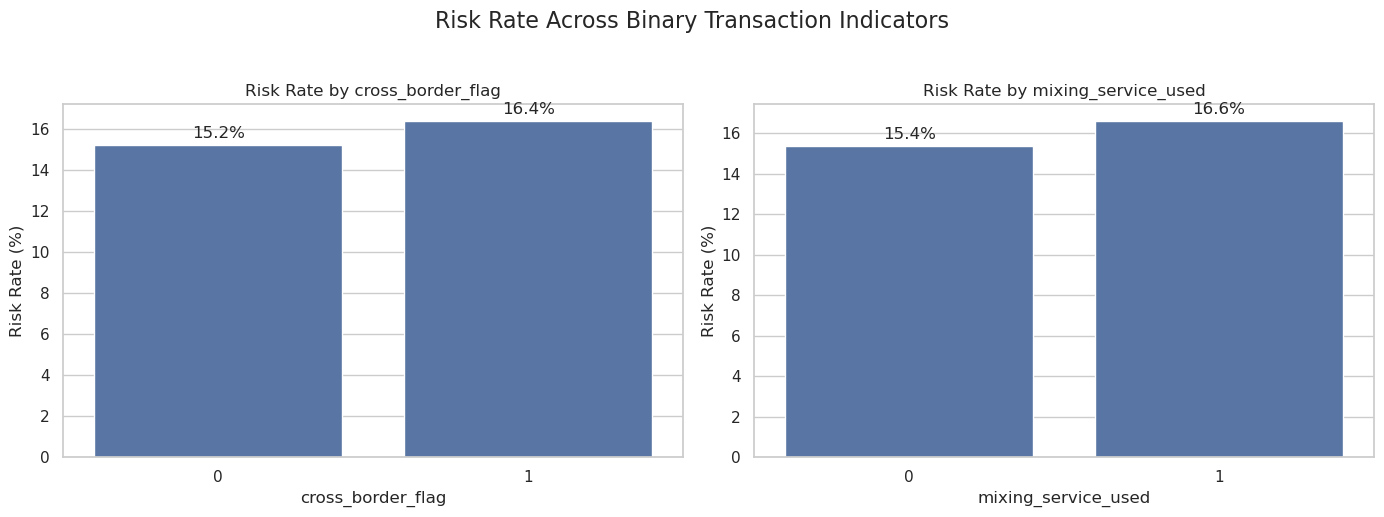

In [31]:
# Visualization
fig, axes = plt.subplots(
    1,
    len(binary_risk_features),
    figsize=(14, 5)
)

for ax, feature in zip(axes, binary_risk_features):
    plot_data = (
        df.groupby(feature)[TARGET]
        .mean()
        .mul(100)
        .reset_index(name="risk_rate")
    )

    sns.barplot(
        data=plot_data,
        x=feature,
        y="risk_rate",
        ax=ax
    )

    ax.set_title(f"Risk Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Risk Rate (%)")

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3
        )

plt.suptitle(
    "Risk Rate Across Binary Transaction Indicators",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

In [32]:
# Data Leakage Investigation

# Check for exact duplicates between features and target
feature_columns = [
    column
    for column in df.columns
    if column != TARGET
]
leakage_summary = []

for feature in feature_columns:
    if df[feature].nunique(dropna=False) <= 1:
        leakage_summary.append({
            "feature": feature,
            "unique_values": df[feature].nunique(dropna=False),
            "target_mean_by_feature": np.nan,
            "potential_issue": "Constant feature"
        })
        continue

    # Calculate target rate for each feature value
    target_rate = (
         df.groupby(feature, dropna=False)[TARGET]
        .mean()
    )
    max_target_rate = target_rate.max()
    min_target_rate = target_rate.min()

    leakage_summary.append({
        "feature": feature,
        "unique_values": df[feature].nunique(dropna=False),
        "target_mean_by_feature": (
            f"{min_target_rate:.3f} - {max_target_rate:.3f}"
        ),
        "potential_issue": (
            "Review"
            if min_target_rate == 0 and max_target_rate == 1
            else "No obvious issue"
        )
    })
leakage_summary = pd.DataFrame(leakage_summary)
display(leakage_summary)    

,feature,unique_values,target_mean_by_feature,potential_issue
0,transaction_id,9000,0.000 - 1.000,Review
1,wallet_id,8593,0.000 - 1.000,Review
2,transaction_amount,8999,0.000 - 1.000,Review
3,transaction_fee,6005,0.000 - 1.000,Review
4,block_confirmation_time,595,0.000 - 0.500,No obvious issue
5,input_count,19,0.129 - 0.182,No obvious issue
6,output_count,19,0.117 - 0.190,No obvious issue
7,wallet_age_days,3563,0.000 - 1.000,Review
8,total_wallet_transactions,5949,0.000 - 1.000,Review
9,avg_wallet_transaction_value,8999,0.000 - 1.000,Review


In [33]:
# Check suspiciously strong numerical relationships
numerical_leakage_check = (
     df[numeric_features + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
    .to_frame("absolute_correlation")
)
print("Numerical Features with Strongest Target Relationships")
print("-" * 55)

display(
    numerical_leakage_check.style.format({
        "absolute_correlation": "{:.4f}"
    })
)

Numerical Features with Strongest Target Relationships
-------------------------------------------------------


,absolute_correlation
output_count,0.0229
block_confirmation_time,0.0208
transaction_fee,0.0208
unusual_pattern_score,0.0193
transaction_velocity_24h,0.0164
cross_border_flag,0.0128
avg_wallet_transaction_value,0.0119
mixing_service_used,0.0103
darknet_association_score,0.0097
total_wallet_transactions,0.0073


In [34]:
# Check whether identifiers are unique
identifier_columns = [
    "transaction_id",
    "wallet_id"
]
identifier_check = []

for column in identifier_columns:
    if column in df.columns:
        identifier_check.append({
            "feature": column,
            "unique_values": df[column].nunique(),
            "total_rows": len(df),
            "uniqueness_ratio": (
                df[column].nunique() / len(df)
            )
        })
identifier_check = pd.DataFrame(identifier_check)
print("\nIdentifier Uniqueness")
print("-" * 55)

display(
    identifier_check.style.format({
        "uniqueness_ratio": "{:.4f}"
    })
)


Identifier Uniqueness
-------------------------------------------------------


,feature,unique_values,total_rows,uniqueness_ratio
0,transaction_id,9000,9000,1.0000
1,wallet_id,8593,9000,0.9548


In [35]:
# Wallet-Level Data Structure & Leakage Check
WALLET_ID =  "wallet_id"

if WALLET_ID not in df.columns:
    raise KeyError(
        f"Required identifier '{WALLET_ID}' was not found in the dataset"
    )
# Transactions per wallet
wallet_transaction_counts = (
    df.groupby(WALLET_ID)
    .size()
    .rename("transaction_count")
)
wallet_summary = pd.DataFrame({
    "wallet_count": [wallet_transaction_counts.shape[0]],
    "single_transaction_wallets": [
        (wallet_transaction_counts == 1).sum()
    ],
    "multi_transaction_wallets": [
        (wallet_transaction_counts > 1).sum()
    ],
    "max_transactions_per_wallet": [
        wallet_transaction_counts.max()
    ]
})
display(wallet_summary)

,wallet_count,single_transaction_wallets,multi_transaction_wallets,max_transactions_per_wallet
0,8593,8193,400,3


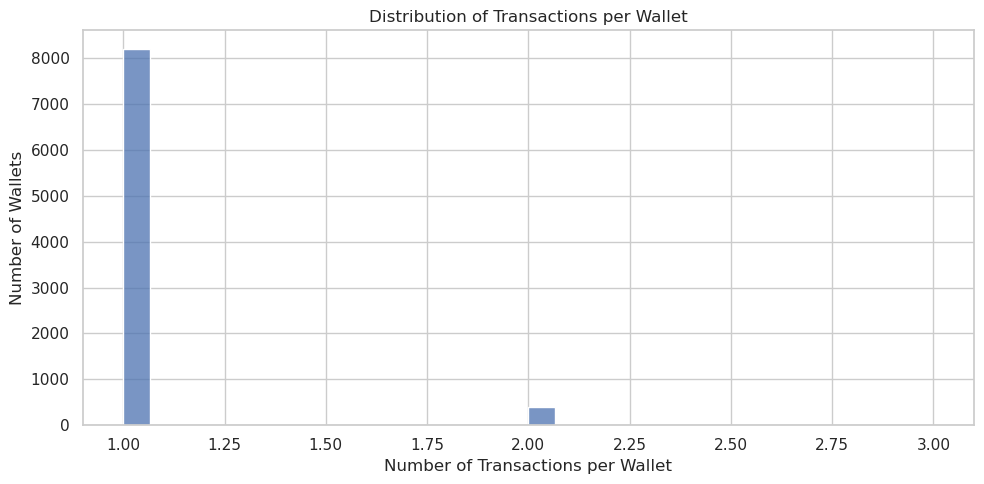

In [36]:
# Distribution of transactions per wallet
plt.figure(figsize=(10, 5))

sns.histplot(
    wallet_transaction_counts,
    bins=30
)
plt.title("Distribution of Transactions per Wallet")
plt.xlabel("Number of Transactions per Wallet")
plt.ylabel("Number of Wallets")

plt.tight_layout()
plt.show()

In [37]:
# Risk-label consistency within wallets
wallet_risk_profile = (
    df.groupby(WALLET_ID)[TARGET]
    .agg(
         transaction_count="count",
        unique_risk_labels="nunique",
        risk_rate="mean"
    )
)
wallet_risk_profile["risk_rate"] = (
    wallet_risk_profile["risk_rate"] * 100
)
# Wallets containing both risk classes
mixed_risk_wallets = (
    wallet_risk_profile["unique_risk_labels"] > 1
).sum()
print(
    f"Wallets containing both risk classes: "
    f"{mixed_risk_wallets:,}"
)

print(
    f"Percentage of wallets with mixed risk labels: "
    f"{mixed_risk_wallets / len(wallet_risk_profile) * 100:.2f}%"
)

Wallets containing both risk classes: 106
Percentage of wallets with mixed risk labels: 1.23%


In [38]:
# Risk consistency summary
risk_consistency = (
    wallet_risk_profile["unique_risk_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("unique_risk_labels")
    .reset_index(name="wallet_count")
)
risk_consistency["percentage"] = (
     risk_consistency["wallet_count"]
    / len(wallet_risk_profile)
    * 100
)
display(
    risk_consistency.style.format({
        "percentage": "{:.2f}%"
    })
)

,unique_risk_labels,wallet_count,percentage
0,1,8487,98.77%
1,2,106,1.23%


In [39]:
def create_transaction_features(data):
    # Make a copy to avoid modifying the original DataFrame
    data = data.copy()

    # Transaction value relative to wallet history
    data["transaction_value_ratio"] = (
        data["transaction_amount"]
        / data["avg_wallet_transaction_value"].replace(0, np.nan)
    )

    # Wallet transaction activity rate
    data["wallet_transaction_rate"] = (
        data["total_wallet_transactions"]
        / data["wallet_age_days"].replace(0, np.nan)
    )

    # Transaction fee relative to transaction value
    data["fee_ratio"] = (
        data["transaction_fee"]
        / data["transaction_amount"].replace(0, np.nan)
    )

    # Transaction structure complexity
    data["transaction_complexity"] = (
        data["input_count"] + data["output_count"]
    )

    # Input-to-output ratio
    data["input_output_ratio"] = (
        data["input_count"]
        / data["output_count"].replace(0, np.nan)
    )

    # Short-term activity relative to historical activity
    data["velocity_to_wallet_activity_ratio"] = (
        data["transaction_velocity_24h"]
        / data["wallet_transaction_rate"].replace(0, np.nan)
    )

    return data
    
# Apply feature engineering
df_model = create_transaction_features(df)

# Replace infinite values created by ratio calculations
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)
# Display newly created features
engineered_features = [
    "transaction_value_ratio",
    "wallet_transaction_rate",
    "fee_ratio",
    "transaction_complexity",
    "input_output_ratio",
    "velocity_to_wallet_activity_ratio"
]
display(
    df_model[engineered_features]
    .describe()
    .T
    .round(4)
)

,count,mean,std,min,25%,50%,75%,max
transaction_value_ratio,9000.0,7.2616,40.6301,0.0003,0.9955,1.9868,3.9841,1622.1006
wallet_transaction_rate,9000.0,12.4996,162.1440,0.0003,1.3045,2.5461,5.1250,9623.0000
fee_ratio,9000.0,0.0012,0.0248,0.0000,0.0001,0.0002,0.0004,2.0821
transaction_complexity,9000.0,19.8467,7.7328,2.0000,14.0000,20.0000,25.0000,38.0000
input_output_ratio,9000.0,1.8431,2.6519,0.0526,0.5263,1.0000,1.9000,19.0000
velocity_to_wallet_activity_ratio,9000.0,230.1082,5179.2816,0.0000,11.3943,33.4695,78.2722,457418.0000


In [40]:

# Engineered Feature Validation

# Create an empty list to store the results
engineered_summary = []

# Validate each engineered feature
for feature in engineered_features:
    series = df_model[feature]

    # Replace infinite values with NaN for statistical calculations
    finite_series = series.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Calculate the first and third quartiles
    q1 = finite_series.quantile(0.25)
    q3 = finite_series.quantile(0.75)

    # Calculate the interquartile range
    iqr = q3 - q1

    # Define the lower and upper outlier boundaries
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identify values outside the boundaries
    outlier_mask = (
        (finite_series < lower_bound) |
        (finite_series > upper_bound)
    )

    # Store statistics for the current feature
    engineered_summary.append({
        "feature": feature,
        "missing_count": series.isna().sum(),
        "missing_percentage": series.isna().mean() * 100,
        "skewness": finite_series.skew(),
        "outlier_count": outlier_mask.sum(),
        "outlier_percentage": outlier_mask.mean() * 100,
        "min": finite_series.min(),
        "median": finite_series.median(),
        "max": finite_series.max()
    })

# Convert the list into a DataFrame AFTER the loop
engineered_summary = pd.DataFrame(engineered_summary)

# Display the validation results
display(
    engineered_summary.style.format({
        "missing_percentage": "{:.2f}%",
        "skewness": "{:.3f}",
        "outlier_percentage": "{:.2f}%",
        "min": "{:.4f}",
        "median": "{:.4f}",
        "max": "{:.4f}"
    })
)

,feature,missing_count,missing_percentage,skewness,outlier_count,outlier_percentage,min,median,max
0,transaction_value_ratio,0,0.00%,20.257,1069,11.88%,0.0003,1.9868,1622.1006
1,wallet_transaction_rate,0,0.00%,43.982,1042,11.58%,0.0003,2.5461,9623.0000
2,fee_ratio,0,0.00%,69.491,1055,11.72%,0.0000,0.0002,2.0821
3,transaction_complexity,0,0.00%,-0.003,0,0.00%,2.0000,20.0000,38.0000
4,input_output_ratio,0,0.00%,3.598,1001,11.12%,0.0526,1.0000,19.0000
5,velocity_to_wallet_activity_ratio,0,0.00%,78.456,978,10.87%,0.0000,33.4695,457418.0000


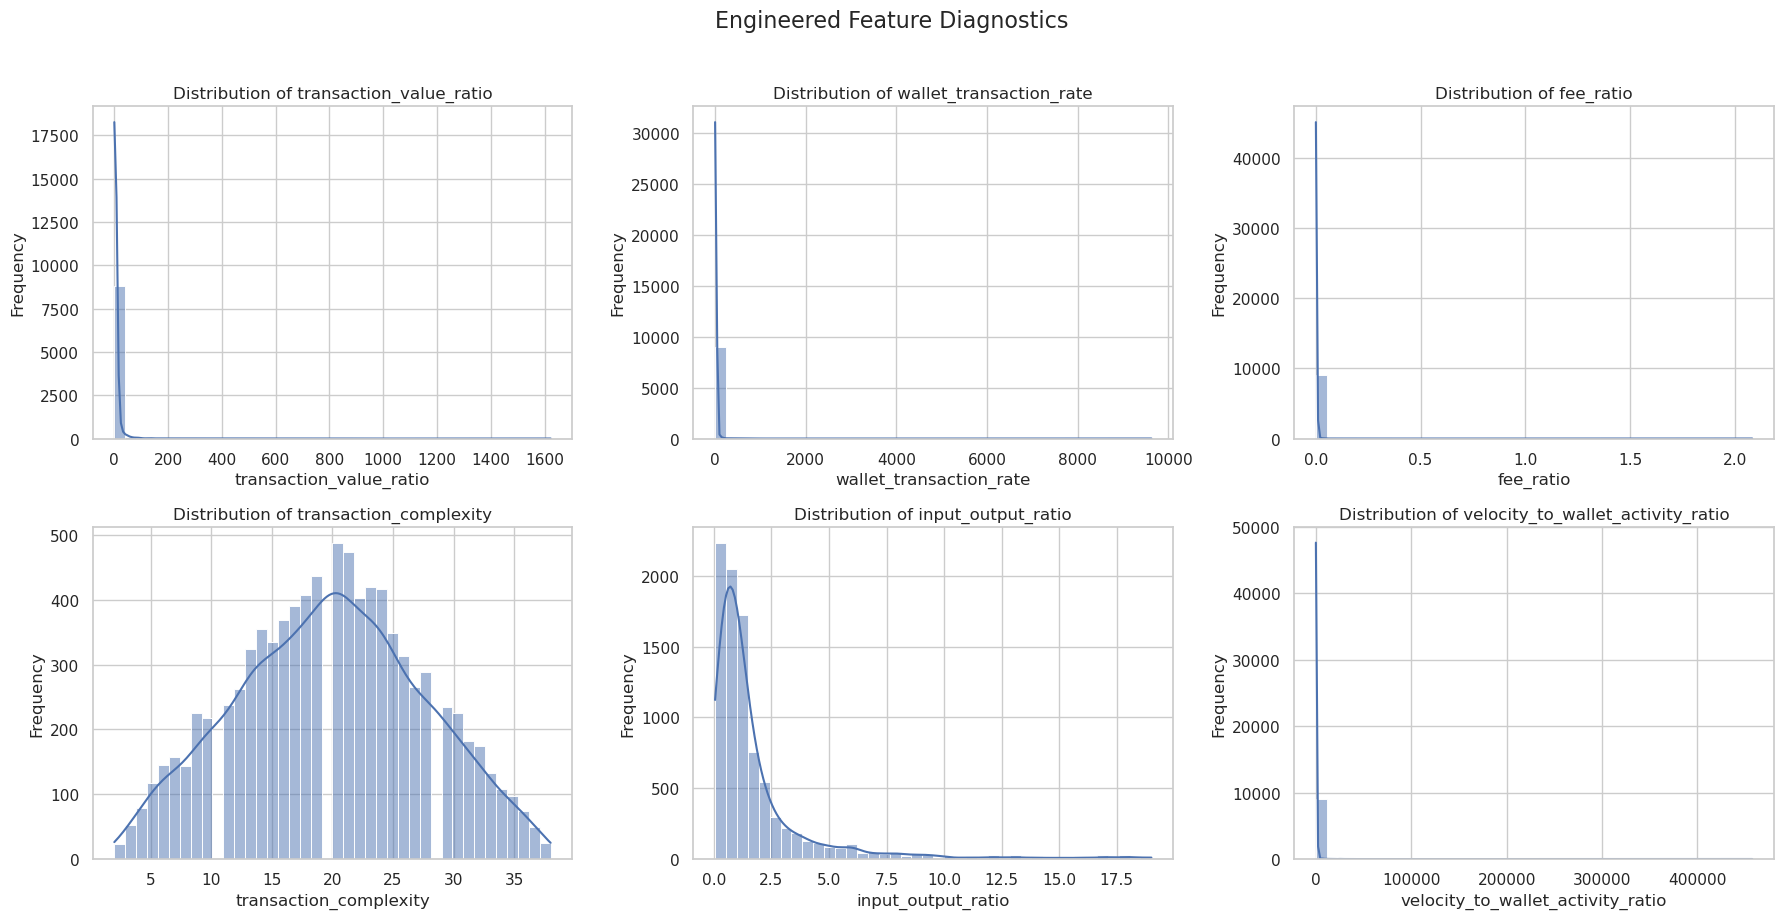

In [41]:

# ------------------------------------------------------------
# Visualize engineered feature distributions
# ------------------------------------------------------------

# Keep only engineered features that exist in df_model
valid_features = [
    feature
    for feature in engineered_features
    if feature in df_model.columns
]

# Check whether any features are available
if not valid_features:
    print("No engineered features available for visualization.")

else:
    # Replace infinite values with NaN for plotting
    plot_data = df_model[valid_features].replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Configure subplot layout
    n_features = len(valid_features)
    n_cols = min(3, n_features)
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows),
        squeeze=False
    )

    # Flatten axes for easy iteration
    axes = axes.flatten()

    # Plot each engineered feature
    for ax, feature in zip(axes, valid_features):
        values = plot_data[feature].dropna()

        if values.empty:
            ax.text(
                0.5, 0.5,
                "No valid data available",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
        else:
            sns.histplot(
                x=values,
                kde=values.nunique() > 1,
                bins=40,
                ax=ax
            )

        ax.set_title(f"Distribution of {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Frequency")

    # Hide unused subplot spaces
    for ax in axes[n_features:]:
        ax.set_visible(False)

    # Add the overall title
    fig.suptitle(
        "Engineered Feature Diagnostics",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

In [42]:
# Engineered Features vs Risk Label
engineered_risk_profile = (
     df_model.groupby(TARGET)[engineered_features]
    .agg(["mean", "median"])
    .T
)
display(
    engineered_risk_profile.round(4)
)
# Correlation with target
engineered_target_correlation = (
    df_model[ engineered_features + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(
        key=abs,
        ascending=False
    )
)
print("Engineered Feature Correlation with Risk Label")
print("-" * 55)
display(
    engineered_target_correlation
    .to_frame(name="correlation")
    .style.format("{:.4f}")
)

risk_label                                       0         1
transaction_value_ratio           mean      7.6251    5.2768
                                  median    1.9937    1.9483
wallet_transaction_rate           mean     13.3480    7.8665
                                  median    2.5512    2.5129
fee_ratio                         mean      0.0012    0.0010
                                  median    0.0002    0.0002
transaction_complexity            mean     19.9103   19.4989
                                  median   20.0000   20.0000
input_output_ratio                mean      1.8309    1.9098
                                  median    1.0000    1.0000
velocity_to_wallet_activity_ratio mean    168.9541  564.0628
                                  median   33.2384   34.8613

Engineered Feature Correlation with Risk Label
-------------------------------------------------------


,correlation
velocity_to_wallet_activity_ratio,0.0276
transaction_value_ratio,-0.0209
transaction_complexity,-0.0192
wallet_transaction_rate,-0.0122
input_output_ratio,0.0108
fee_ratio,-0.0033


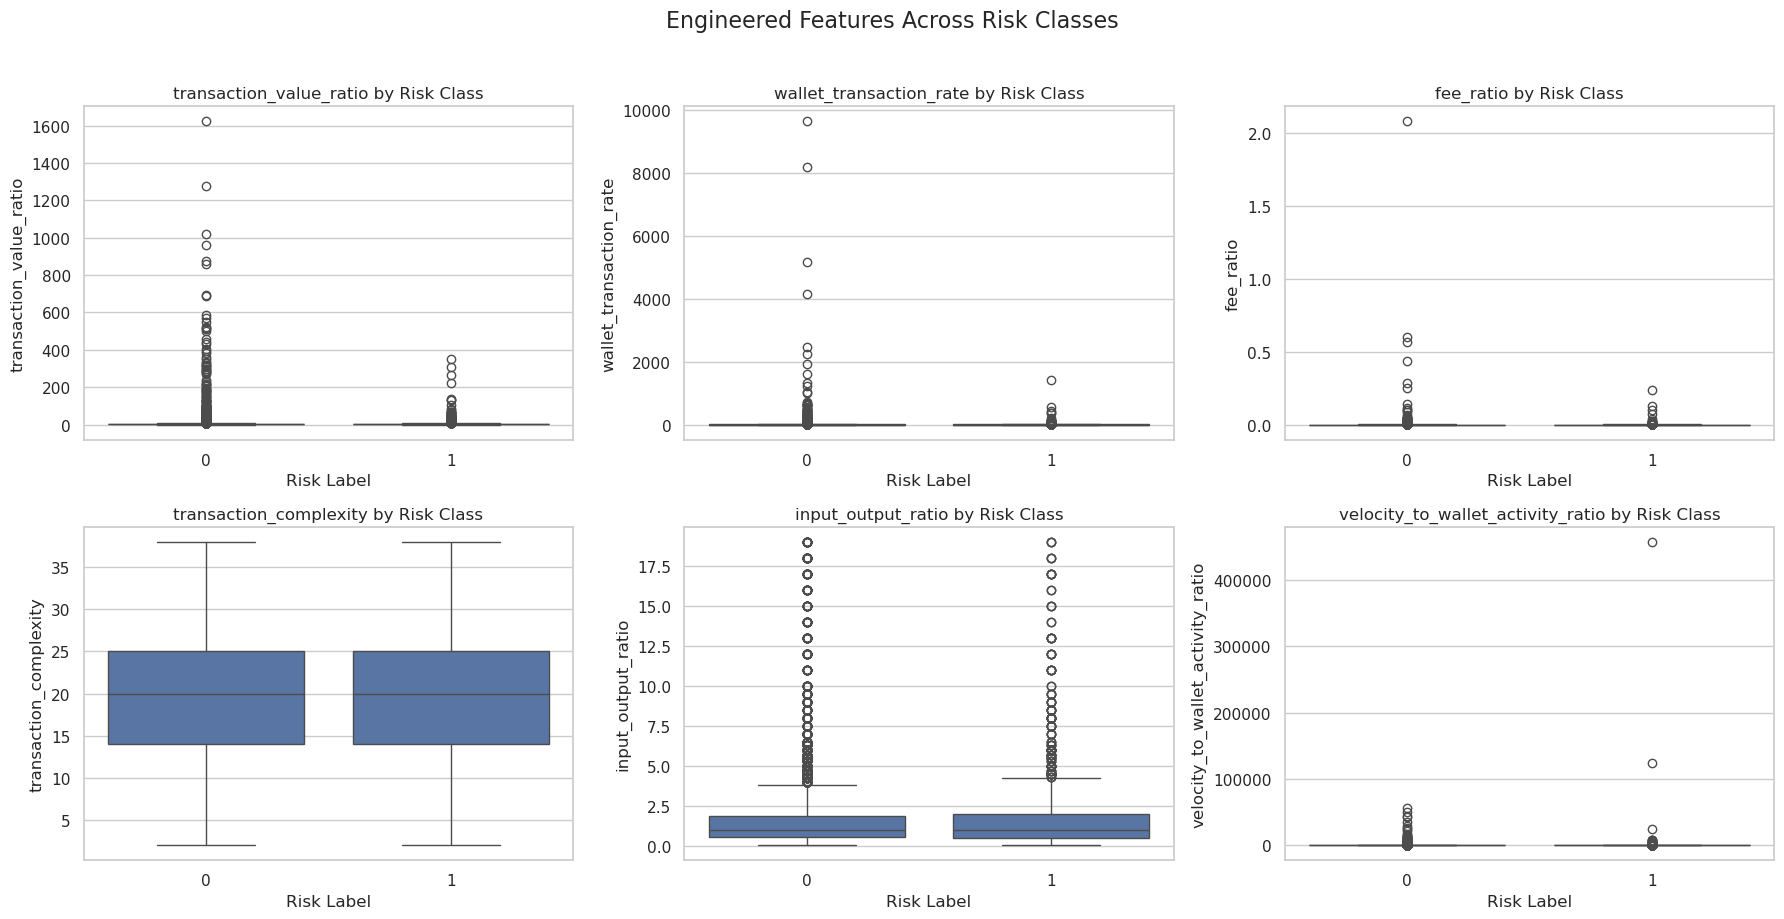

In [43]:
# Visualize engineered feature distributions
n_features = len(engineered_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(
    axes,
    engineered_features
):
    sns.boxplot(
        data=df_model,
        x=TARGET,
        y=feature,
        ax=ax
    )
    ax.set_title(
        f"{feature} by Risk Class"
    )
    ax.set_xlabel("Risk Label")
    ax.set_ylabel(feature)

for ax in axes[n_features:]:
    ax.set_visible(False)

plt.suptitle(
    "Engineered Features Across Risk Classes",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()   

In [44]:

# Modeling Feature Definition

# Define columns to exclude from modeling
EXCLUDED_FEATURES = {
    "transaction_id",
    "wallet_id",
    TARGET
}

# Build candidate feature set
candidate_features = [
    column
    for column in df_model.columns
    if column not in EXCLUDED_FEATURES
    and pd.api.types.is_numeric_dtype(df_model[column])
]

# Validate feature selection
if not candidate_features:
    raise ValueError(
        "No valid numerical features were found for modeling."
    )

# Create modeling dataset
X = df_model[candidate_features].copy()
y = df_model[TARGET].copy()

# Feature overview
feature_overview = pd.DataFrame({
    "feature": candidate_features,
    "dtype": X.dtypes.astype(str).values,
    "missing_count": X.isna().sum().values,
    "unique_values": X.nunique().values
})

display(feature_overview)

print(f"Number of candidate features: {len(candidate_features)}")
print(f"Number of observations     : {len(X):,}")

print("\nExcluded columns:")
for column in sorted(EXCLUDED_FEATURES):
    if column in df_model.columns:
        print(f"  - {column}")

,feature,dtype,missing_count,unique_values
0,transaction_amount,float64,0,8999
1,transaction_fee,float64,0,6005
2,block_confirmation_time,int64,0,595
3,input_count,int64,0,19
4,output_count,int64,0,19
5,wallet_age_days,int64,0,3563
6,total_wallet_transactions,int64,0,5949
7,avg_wallet_transaction_value,float64,0,8999
8,cross_border_flag,int64,0,2
9,mixing_service_used,int64,0,2


Number of candidate features: 19
Number of observations     : 9,000

Excluded columns:
  - risk_label
  - transaction_id
  - wallet_id


In [45]:
# Train / Test Split Strategy
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# Configuration
TEST_SIZE = 0.20
RANDOM_STATE = 42

wallet_count = df_model[WALLET_ID].nunique()
row_count = len(df_model)

wallet_repetition_ratio = (
     1 - wallet_count / row_count
)
print(f"Total observations       : {row_count:,}")
print(f"Unique wallets           : {wallet_count:,}")
print(f"Wallet repetition ratio  : {wallet_repetition_ratio:.2%}")

Total observations       : 9,000
Unique wallets           : 8,593
Wallet repetition ratio  : 4.52%


In [46]:
# Determine split strategy
if wallet_count < row_count:
    split_strategy = "GroupShuffleSplit"

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE        
    )
    train_indices, test_indices = next(
         splitter.split(
            X,
            y,
            groups=df_model[WALLET_ID]
         )
    )
    X_train = X.iloc[train_indices].copy()
    X_test = X.iloc[test_indices].copy()

    y_train = y.iloc[train_indices].copy()
    y_test = y.iloc[test_indices].copy()

    train_wallets = set(
        df_model.iloc[train_indices][WALLET_ID]
    )
    test_wallets = set(
        df_model.iloc[test_indices][WALLET_ID]
    )
else:
    split_strategy = "Stratified Train/Test Split"

    X_train, X_test, y_train, y_test = train_test_split(
        X, 
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y      
        
    )
    train_wallets = set(
        df_model.loc[X_train.index, WALLET_ID]
    )
    test_wallets = set(
        df_model.loc[X_test.index, WALLET_ID]
    )

# Validate split
wallet_overlap = train_wallets.intersection(
     test_wallets
)
print(f"\nSplit strategy: {split_strategy}")

print(f"Training Samples: {len(X_train):,}")
print(f"Test Samples: {len(X_test):,}")

print(
    f"\nTraining target distribution:\n"
    f"{y_train.value_counts(normalize=True).sort_index().mul(100).round(2)}"
)

print(
    f"\nTest target distribution:\n"
    f"{y_test.value_counts(normalize=True).sort_index().mul(100).round(2)}"
)

print(
    f"\nWallet overlap between train/test: "
    f"{len(wallet_overlap):,}"
)

if wallet_overlap:
    print(
        "WARNING: Some wallets appear in both training and test sets."
    )
else:
    print(
        "Wallet leakage check passed: "
        "no wallet appears in both training and test sets."
    )


Split strategy: GroupShuffleSplit
Training Samples: 7,203
Test Samples: 1,797

Training target distribution:
risk_label
0    84.67
1    15.33
Name: proportion, dtype: float64

Test target distribution:
risk_label
0    83.92
1    16.08
Name: proportion, dtype: float64

Wallet overlap between train/test: 0
Wallet leakage check passed: no wallet appears in both training and test sets.


In [47]:
# Baseline Model — Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Model configuration
baseline_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]    
)
# Train baseline model
baseline_model.fit(
    X_train,
    y_train
)
# Generate predictions
y_pred_baseline = baseline_model.predict(X_test)
y_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]

# Evaluate baseline model
baseline_metrics = {
    "model": "Logistic Regression",
    "accuracy": accuracy_score(
        y_test,
        y_pred_baseline
    ),
    "precision": precision_score(
        y_test,
        y_pred_baseline,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        y_pred_baseline,
        zero_division=0
    ),
    "f1": f1_score(
        y_test,
        y_pred_baseline,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        y_proba_baseline
    ),
    "pr_auc": average_precision_score(
        y_test,
        y_proba_baseline
    )
}
baseline_results = pd.DataFrame(
    [baseline_metrics]
)
display(
    baseline_results.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.5147,0.1669,0.5052,0.2509,0.5147,0.1752


In [48]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Model configuration
random_forest_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)
# Train Random Forest
random_forest_model.fit(
    X_train,
    y_train
)
# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)
y_proba_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate Random Forest
rf_metrics = {
    "model": "Random Forest",
    "accuracy": accuracy_score(
        y_test,
        y_pred_rf
    ),
    "precision": precision_score(
        y_test,
        y_pred_rf,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        y_pred_rf,
        zero_division=0
    ),
    "f1": f1_score(
        y_test,
        y_pred_rf,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        y_proba_rf
    ),
    "pr_auc": average_precision_score(
        y_test,
        y_proba_rf
    )
}

rf_results = pd.DataFrame(
    [rf_metrics]
)

display(
    rf_results.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.8392,0.0000,0.0000,0.0000,0.5041,0.1753


In [49]:
# XGBoost
from xgboost import XGBClassifier

# Model configuration
xgboost_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=5,
                min_child_weight=2,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)
# Train XGBoost
xgboost_model.fit(
    X_train,
    y_train
)
# Generate predictions
y_pred_xgb = xgboost_model.predict(X_test)
y_proba_xgb = xgboost_model.predict_proba(X_test)[:, 1]

# Evaluate XGBoost
xgb_metrics = {
    "model": "XGBoost",
    "accuracy": accuracy_score(
        y_test,
        y_pred_xgb
    ),
    "precision": precision_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    ),
    "f1": f1_score(
        y_test,
        y_pred_xgb,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        y_proba_xgb
    ),
    "pr_auc": average_precision_score(
        y_test,
        y_proba_xgb
    )
}

xgb_results = pd.DataFrame(
    [xgb_metrics]
)

display(
    xgb_results.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,XGBoost,0.8392,0.5000,0.0035,0.0069,0.5174,0.1823


In [50]:
# Model Performance Comparison

# Combine model results
model_comparison = pd.concat(
    [
     baseline_results,
        rf_results,
        xgb_results
    ],                     
    ignore_index=True
)
# Sort by PR-AUC as the primary metric
model_comparison = (
    model_comparison
    .sort_values(
        by="pr_auc",
        ascending=False
    )
    .reset_index(drop=True)
)
# Display comparison table
display(
    model_comparison.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,XGBoost,0.8392,0.5000,0.0035,0.0069,0.5174,0.1823
1,Random Forest,0.8392,0.0000,0.0000,0.0000,0.5041,0.1753
2,Logistic Regression,0.5147,0.1669,0.5052,0.2509,0.5147,0.1752


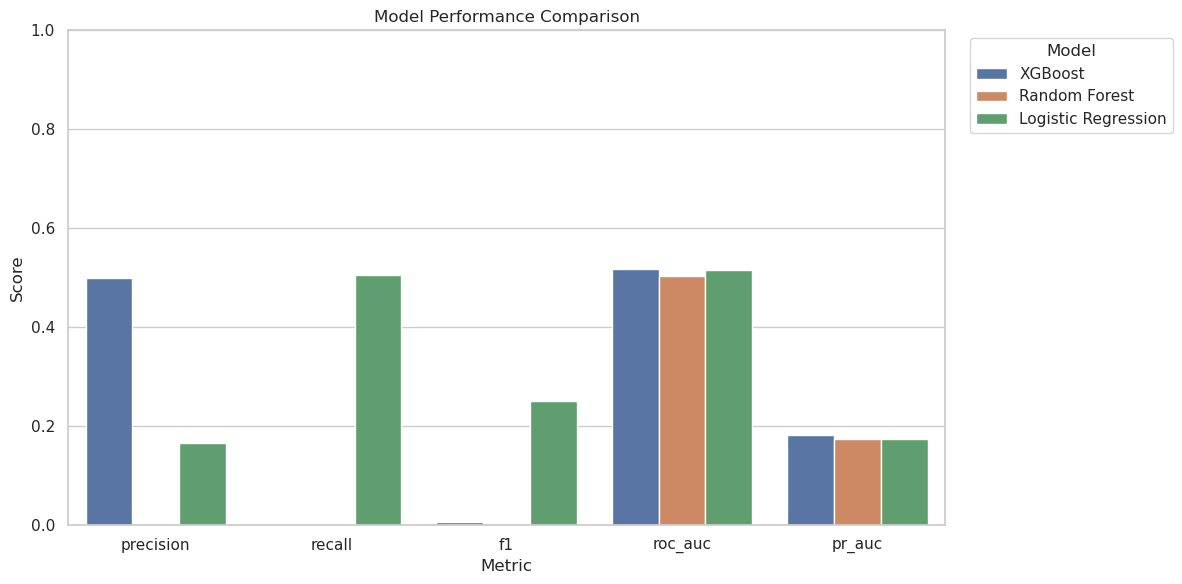

In [51]:
# Visual comparison
comparison_metrics = [
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]
plot_data = model_comparison.melt(
    id_vars="model",
    value_vars=comparison_metrics,
    var_name="metric",
    value_name="score"
)
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="metric",
    y="score",
    hue="model"
)
plt.title("Model Performance Comparison")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [52]:
# Best model based on PR-AUC
best_model_name = model_comparison.iloc[0]["model"]

print(
    f"Best baseline model based on PR-AUC: "
    f"{best_model_name}"
)

Best baseline model based on PR-AUC: XGBoost


In [53]:
# Detailed Evaluation — Confusion Matrix

# Select predictions from the best baseline model
prediction_map = {
    "Logistic Regression": (
        y_pred_baseline,
        y_proba_baseline
    ),
    "Random Forest": (
        y_pred_rf,
        y_proba_rf
    ),
    "XGBoost": (
        y_pred_xgb,
        y_proba_xgb
    )
}
if best_model_name not in prediction_map:
    raise ValueError(
        f"Predictions for {best_model_name} are not available"
    )
y_pred_best, y_proba_best = prediction_map[
     best_model_name
]
# Classification report
print( f"Classification Report — {best_model_name}")
print("-" * 60)
print(
    classification_report(
        y_test,
        y_pred_best,
        digits=4,
        zero_division=0
    )
)

Classification Report — XGBoost
------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.8396    0.9993    0.9125      1508
           1     0.5000    0.0035    0.0069       289

    accuracy                         0.8392      1797
   macro avg     0.6698    0.5014    0.4597      1797
weighted avg     0.7849    0.8392    0.7669      1797



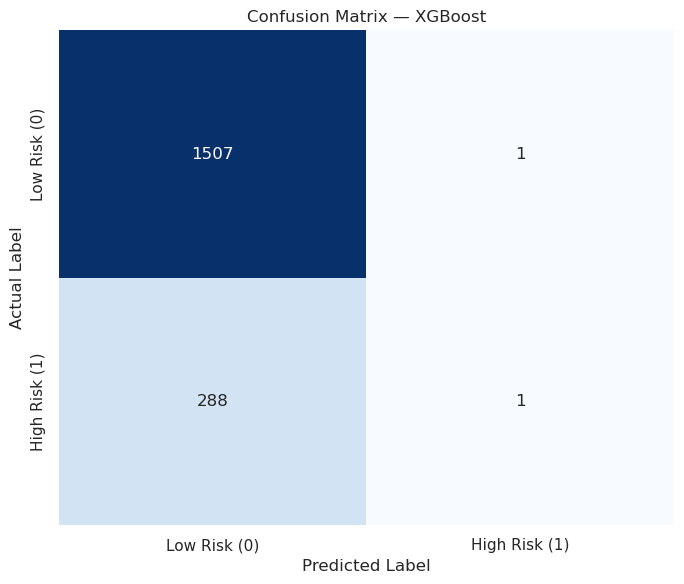

In [54]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_best
)
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Low Risk (0)", "High Risk (1)"],
    yticklabels=["Low Risk (0)", "High Risk (1)"]
)
plt.title(
    f"Confusion Matrix — {best_model_name}"
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

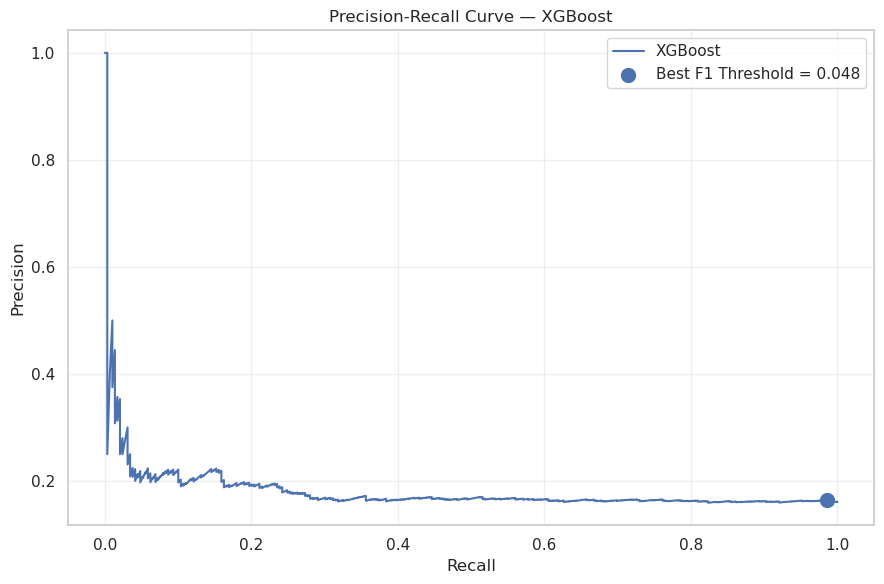

In [58]:
# Precision-Recall Curve & Threshold Analysis

# Calculate precision-recall values
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test,
        y_proba_best
    )
)
# F1 score for each threshold
f1_values = (
    2
    * precision_values[:-1]
    * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-10
    )
)
# Identify threshold with maximum F1
best_threshold_index = np.argmax(f1_values)
best_threshold = thresholds[best_threshold_index]
best_f1 = f1_values[best_threshold_index]

best_precision = precision_values[
     best_threshold_index
]
best_recall = recall_values[
     best_threshold_index
]
# Precision-Recall Curve
plt.figure(figsize=(9, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"{best_model_name}"
)
plt.scatter(
    best_recall,
    best_precision,
    s=100,
    label=f"Best F1 Threshold = {best_threshold:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    f"Precision-Recall Curve — {best_model_name}"
)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
# Threshold performance
threshold_analysis = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1],
    "f1": f1_values
})
display(
    threshold_analysis
    .sort_values("f1", ascending=False)
    .head(10)
    .style.format({
        "threshold": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}"
    })
)
print(
    f"Best threshold based on F1: {best_threshold:.4f}"
)
print(
    f"Precision at threshold    : {best_precision:.4f}"
)
print(
    f"Recall at threshold       : {best_recall:.4f}"
)
print(
    f"F1-score at threshold     : {best_f1:.4f}"
)


,threshold,precision,recall,f1
63,0.0477,0.1644,0.9862,0.2818
62,0.0477,0.1643,0.9862,0.2816
61,0.0477,0.1642,0.9862,0.2815
60,0.0476,0.1641,0.9862,0.2813
59,0.0474,0.1640,0.9862,0.2812
58,0.0472,0.1639,0.9862,0.2811
57,0.0463,0.1638,0.9862,0.2809
64,0.0477,0.1639,0.9827,0.2809
56,0.0461,0.1637,0.9862,0.2808
55,0.0460,0.1636,0.9862,0.2806


Best threshold based on F1: 0.0477
Precision at threshold    : 0.1644
Recall at threshold       : 0.9862
F1-score at threshold     : 0.2818


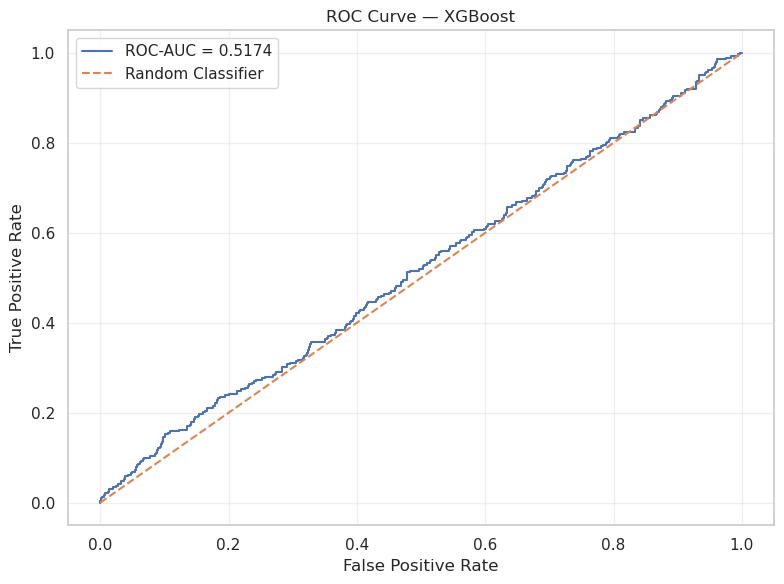

In [79]:
# ROC-AUC & Precision-Recall AUC

# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_proba_best
)
roc_auc =  roc_auc_score(
    y_test,
    y_proba_best
)

# Calculate Precision-Recall AUC
pr_auc = average_precision_score(
    y_test,
    y_proba_best
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    f"ROC Curve — {best_model_name}"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

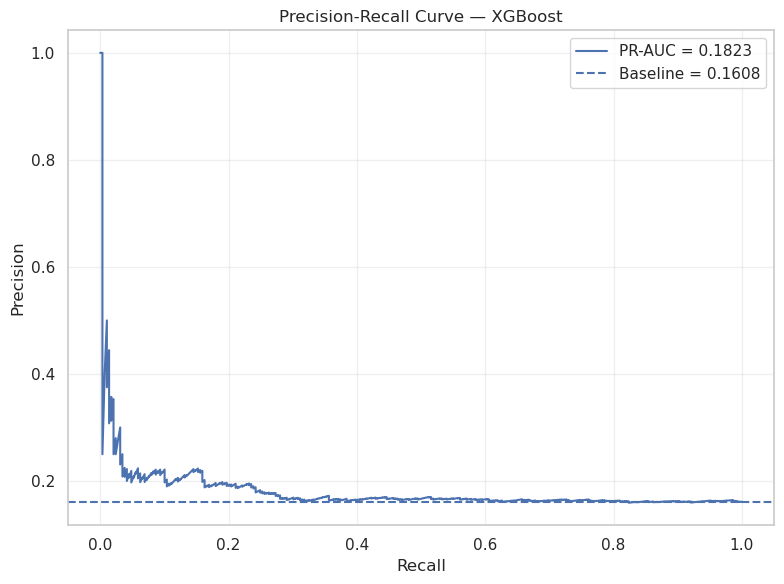

In [80]:
# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR-AUC = {pr_auc:.4f}"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"Baseline = {y_test.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    f"Precision-Recall Curve — {best_model_name}"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [86]:
# Feature Importance Analysis

# Select the fitted tree-based model
tree_models = {
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}
if best_model_name not in tree_models:
     print(
        f"Feature importance from tree models is not applicable "
        f"to {best_model_name}."
    )
else:
    selected_pipeline = tree_models[best_model_name]

    # Extract fitted classifier from pipeline
    fitted_classifier = selected_pipeline.named_steps["classifier"]

    # Extract feature importance
    feature_importance = pd.DataFrame({
        "feature": candidate_features,
        "importance": fitted_classifier.feature_importances_
    })
    # Sort by importance
    feature_importance = (
        feature_importance
        .sort_values(
            "importance",
            ascending=False
        )
        .reset_index(drop=True)
    )
    # Display top features
    top_n = min(15, len(feature_importance))

    print(
        f"Top {top_n} Features — {best_model_name}"
    )
    print("-" * 55)

    display(
        feature_importance.head(top_n).style.format({
            "importance": "{:.4f}"
        })
    )

Top 15 Features — XGBoost
-------------------------------------------------------


,feature,importance
0,transaction_amount,0.0572
1,darknet_association_score,0.0558
2,transaction_value_ratio,0.0554
3,transaction_fee,0.0554
4,block_confirmation_time,0.0553
5,unusual_pattern_score,0.0550
6,velocity_to_wallet_activity_ratio,0.0547
7,transaction_velocity_24h,0.0545
8,wallet_age_days,0.0543
9,fee_ratio,0.0538


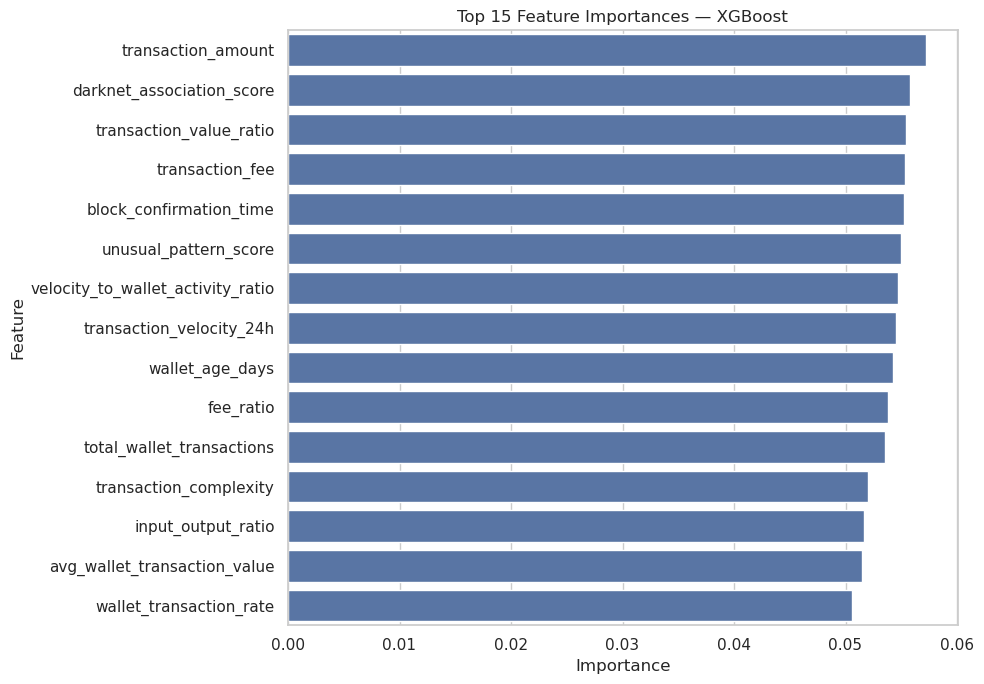

In [87]:
# Visualization
plt.figure(
        figsize=(10, 7)
    )

sns.barplot(
    data=feature_importance.head(top_n),
    x="importance",
    y="feature"
)

plt.title(
    f"Top {top_n} Feature Importances — {best_model_name}"
)
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

"""
The findings from the Blockchain Transaction Risk Detection analysis demonstrate that blockchain transactions are exposed to measurable financial and security risks, which can be assessed using machine-learning techniques based on transaction characteristics, wallet activity, mixing-service usage, darknet association scores and unusual transaction patterns. Out of the 9,000 transactions analyzed, 1,393 (15.48%) were labeled high risk, indicating the importance of effective transaction monitoring. Although XGBoost achieved an overall accuracy of 83.92%, its high-risk recall of only 0.35% at the default classification threshold shows that it failed to identify almost all high-risk transactions, demonstrating that accuracy alone is insufficient for evaluating risk-detection effectiveness. Adjusting the threshold to 0.0477 increased recall to 98.62%, but precision declined to 16.44%, highlighting the trade-off between detecting suspicious transactions and generating false positives. These results suggest that machine learning can support blockchain risk management, but its effectiveness depends on appropriate threshold selection, reliable risk labels, improved model performance and validation using independent real-world transaction data. Therefore, blockchain transaction risk should be managed through continuous monitoring and evidence-based risk assessment rather than relying solely on automated classifications, since a transaction identified as high risk does not necessarily constitute illegal activity.
"""